# Quarter-Car Wheel H∞ Control: From Road Disturbance to Robust Ride

This notebook builds the quarter-car active-suspension example in the same staged style as the cart-pole control tutorials:

1. [Quarter-car dynamics and equilibrium model](#part-1-quarter-car-dynamics)
2. [State-space and open-loop analysis](#part-2-state-space-open-loop-analysis)
3. [Static-weight H∞ state feedback](#part-3-static-weight-hinf-state-feedback)
4. [H∞ observer and static-weight output feedback](#part-4-hinf-observer-output-feedback)
5. [Frequency-shaped H∞ performance](#part-5-frequency-shaped-hinf)
6. [$S/T/KS$ mixed-sensitivity synthesis](#part-6-mixed-sensitivity-comparison)


> **Video note:** Solver updates mean the gains, poles, and plots here may differ from the earlier YouTube video. The qualitative takeaway remains: for this example, dynamic weighting and mixed-sensitivity shaping improve the plotted responses relative to the static-weight baseline.


<a id="part-1-quarter-car-dynamics"></a>
## Part 1 - Quarter-Car Dynamics and Equilibrium Model

The active quarter-car model consists of a sprung body mass, an unsprung wheel mass, a suspension spring and dashpot, a tire spring, and an actuator between the body and wheel:

- $m_b$: body (sprung) mass (kg)
- $m_w$: wheel (unsprung) mass (kg)
- $k_s$: suspension spring stiffness (N/m)
- $c_s$: suspension dashpot coefficient (N·s/m)
- $k_t$: tire stiffness (N/m)
- $x_b$: perturbed body displacement (m)
- $x_w$: perturbed wheel displacement (m)
- $z_{r}$: road displacement (m)
- $f_c$: actuator force applied between the body and wheel (N)

The state-space model below is written directly in these perturbation variables. Gravity and static preload are therefore absent; they are already absorbed into the equilibrium offset. The incremental spring and dashpot forces depend on relative perturbation motion:

$$
m_b\ddot{x}_b
= f_c-k_s(x_b-x_w)-c_s(\dot{x}_b-\dot{x}_w),
$$

$$
m_w\ddot{x}_w
= -f_c+k_s(x_b-x_w)+c_s(\dot{x}_b-\dot{x}_w)-k_t(x_w-r).
$$


In [1]:
# ruff: noqa: E741, F401, I001
import matplotlib.pyplot as plt
import control as ct
import numpy as np
from IPython.display import display
from scipy.linalg import expm
from scipy.integrate import quad_vec
from scipy.signal import StateSpace, lsim
import akreon_native.controls as controls
from akreon_native.controls import SolverConfig
from akreon_native.plot import (
    plot_poles,
    plot_bode_responses,
    plot_state_step_responses,
    plot_state_trajectories,
    plot_shadow_price_summary,
)

In [2]:
# Call the installed control bindings directly.
print("Control bindings:", controls.__name__)


Control bindings: akreon_native.controls


<a id="part-2-state-space-open-loop-analysis"></a>
## Part 2 - State-Space and Open-Loop Analysis

Let $z$ be the interleaved perturbation state vector

$$
z=\begin{bmatrix}x_b & \dot{x}_b & x_w & \dot{x}_w\end{bmatrix}^{\mathsf T}.
$$

With road perturbation $w=r$ and actuator force $u=f_c$, the continuous-time plant is

$$
\dot z=Az+B_w w+B_u u,
$$

where

$$
A=\begin{bmatrix}
0 & 1 & 0 & 0\\
-k_s/m_b & -c_s/m_b & k_s/m_b & c_s/m_b\\
0 & 0 & 0 & 1\\
k_s/m_w & c_s/m_w & -(k_s+k_t)/m_w & -c_s/m_w
\end{bmatrix},\qquad
B_w=\begin{bmatrix}0\\0\\0\\k_t/m_w\end{bmatrix},\qquad
B_u=\begin{bmatrix}0\\1/m_b\\0\\-1/m_w\end{bmatrix}.
$$

For the later observer design, use suspension travel and inertial body velocity. This avoids feeding back absolute body/wheel positions as if the controller should regulate a permanent road-height offset back to zero.

$$
y=C_yz,
\qquad
y=\begin{bmatrix}x_b-x_w\\\dot{x}_b\end{bmatrix},
\qquad
C_y=\begin{bmatrix}1&0&-1&0\\0&1&0&0\end{bmatrix}.
$$


### Representative Pickup / Light-Truck Parameters

The numerical example uses an approximate but representative front-corner model for a midsize pickup or light truck. 


In [3]:
# Representative midsize-pickup/light-truck front-corner model.
m_b = 450.0  # sprung body mass [kg]
m_w = 65.0  # unsprung wheel assembly mass [kg]
k_s = 40_000.0  # suspension wheel rate [N/m]
c_s = 3_000.0  # equivalent viscous suspension dashpot [N s/m]
k_t = 200_000.0  # effective tire vertical stiffness [N/m]

STATE_LABELS = [
    "Body perturbation\n$x_b$",
    "Body Velocity\n$\\dot{x}_b$",
    "Wheel perturbation\n$x_w$",
    "Wheel Velocity\n$\\dot{x}_w$",
]
MEASUREMENT_LABELS = [r"Suspension travel $x_b-x_w$", r"Body velocity $\dot{x}_b$"]
MEASUREMENT_UNITS = ["m", "m/s"]

print(f"Sprung mass m_b: {m_b:.1f} kg")
print(f"Unsprung mass m_w: {m_w:.1f} kg")
print(f"Suspension wheel rate k_s: {k_s / 1_000.0:.1f} kN/m")
print(f"Dashpot coefficient c_s: {c_s:.0f} N s/m")
print(f"Tire stiffness k_t: {k_t / 1_000.0:.1f} kN/m")

Sprung mass m_b: 450.0 kg
Unsprung mass m_w: 65.0 kg
Suspension wheel rate k_s: 40.0 kN/m
Dashpot coefficient c_s: 3000 N s/m
Tire stiffness k_t: 200.0 kN/m


In [4]:
A = np.array(
    [
        [0.0, 1.0, 0.0, 0.0],
        [-k_s / m_b, -c_s / m_b, k_s / m_b, c_s / m_b],
        [0.0, 0.0, 0.0, 1.0],
        [k_s / m_w, c_s / m_w, -(k_s + k_t) / m_w, -c_s / m_w],
    ],
    dtype=np.float64,
)

B_w = np.array([[0.0], [0.0], [0.0], [k_t / m_w]], dtype=np.float64)
B_u = np.array([[0.0], [1.0 / m_b], [0.0], [-1.0 / m_w]], dtype=np.float64)
B = np.hstack((B_w, B_u))  # generalized input order: [w, u]

C_y = np.array([[1.0, 0.0, -1.0, 0.0], [0.0, 1.0, 0.0, 0.0]], dtype=np.float64)
D_y = np.zeros((C_y.shape[0], B.shape[1]), dtype=np.float64)

quarter_car_ss = ct.ss(A, B, C_y, D_y)

print(f"A =\n{A}")
print(f"B_w =\n{B_w}")
print(f"B_u =\n{B_u}")
print(f"C_y =\n{C_y}")

A =
[[ 0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [-8.88888889e+01 -6.66666667e+00  8.88888889e+01  6.66666667e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]
 [ 6.15384615e+02  4.61538462e+01 -3.69230769e+03 -4.61538462e+01]]
B_w =
[[   0.        ]
 [   0.        ]
 [   0.        ]
 [3076.92307692]]
B_u =
[[ 0.        ]
 [ 0.00222222]
 [ 0.        ]
 [-0.01538462]]
C_y =
[[ 1.  0. -1.  0.]
 [ 0.  1.  0.  0.]]


### Open-Loop Poles

The open-loop poles expose the body-bounce and wheel-hop modes of the passive suspension. The passive spring and dashpot should place both modal pairs in the open left half plane.


Open loop poles: [-24.00023102+53.80543348j -24.00023102-53.80543348j
  -2.41002539 +8.54329755j  -2.41002539 -8.54329755j]
Is open loop stable? True


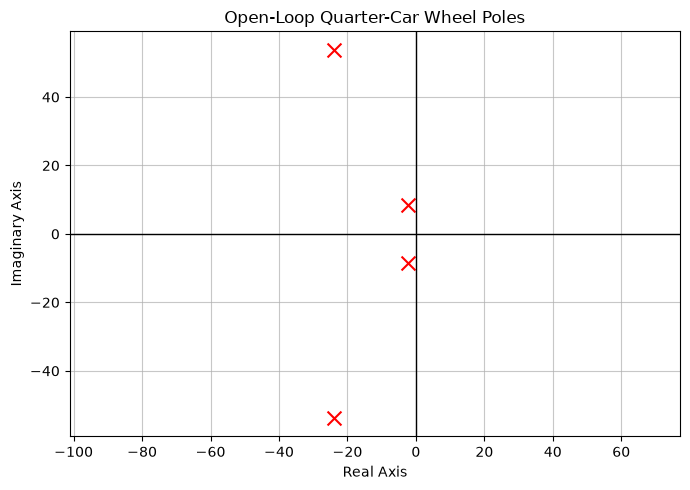

In [5]:
open_loop_poles = ct.poles(quarter_car_ss)
is_open_loop_stable = np.all(np.real(open_loop_poles) < 0.0)

print(f"Open loop poles: {open_loop_poles}")
print(f"Is open loop stable? {is_open_loop_stable}")
plot_poles(open_loop_poles, title="Open-Loop Quarter-Car Wheel Poles")

### Controllability Matrix

The actuator can control every state direction when the Cayley-Hamilton controllability matrix has full row rank:

$$
\mathcal C=\begin{bmatrix}B_u&AB_u&A^2B_u&\cdots&A^{n-1}B_u\end{bmatrix},\qquad
\operatorname{rank}(\mathcal C)=n.
$$


In [6]:
Ctrb = ct.ctrb(A, B_u)
ctrb_rank = np.linalg.matrix_rank(Ctrb)

print(f"Controllability matrix =\n{Ctrb}")
print(f"Controllability rank: {ctrb_rank}/{A.shape[0]}")

Controllability matrix =
[[ 0.00000000e+00  2.22222222e-03 -1.17378917e-01  4.63496238e+00]
 [ 2.22222222e-03 -1.17378917e-01  4.63496238e+00  1.53427626e+02]
 [ 0.00000000e+00 -1.53846154e-02  8.12623274e-01  1.52490770e+01]
 [-1.53846154e-02  8.12623274e-01  1.52490770e+01 -3.56257056e+03]]
Controllability rank: 4/4


### Finite-Horizon Controllability Gramian

Rank is a binary test. The finite-horizon controllability Gramian also indicates how strongly actuator energy reaches different state-space directions:

$$
W_c(t_f)=\int_0^{t_f}e^{At}B_uB_u^{\mathsf T}e^{A^{\mathsf T}t}\,dt.
$$

Large eigenvalues identify directions that are easier to move; small eigenvalues identify directions requiring more actuator energy. Because positions and velocities have different physical units, this plot is primarily a conditioning diagnostic. A quantitative energy comparison should first scale the states by meaningful allowable magnitudes.

In [7]:
def ctrb_gram_integrand(t):
    eAt = expm(A * t)
    return eAt @ B_u @ B_u.T @ eAt.T


time_horizons = np.linspace(0.05, 1.0, 10)
W_c_eigs_sweep = []
W_c_weakest_state_impact = []
W_c_dominant_state_impact = []
for horizon in time_horizons:
    W_c, _ = quad_vec(ctrb_gram_integrand, 0.0, horizon)
    W_c = 0.5 * (W_c + W_c.T)
    W_c_eigs, W_c_vecs = np.linalg.eigh(W_c)
    W_c_eigs_sweep.append(W_c_eigs)
    W_c_weakest_state_impact.append(W_c_eigs[0] * W_c_vecs[:, 0] ** 2)
    W_c_dominant_state_impact.append(W_c_eigs[-1] * W_c_vecs[:, -1] ** 2)

W_c_eigs_sweep = np.asarray(W_c_eigs_sweep)
W_c_weakest_state_impact = np.asarray(W_c_weakest_state_impact)
W_c_dominant_state_impact = np.asarray(W_c_dominant_state_impact)

### Observability From Suspension Travel and Body Velocity

Before designing an observer, verify that the two displacement measurements contain enough information to reconstruct all four states:

$$
\mathcal O=\begin{bmatrix}C_y\\C_yA\\C_yA^2\\\vdots\\C_yA^{n-1}\end{bmatrix},\qquad
\operatorname{rank}(\mathcal O)=n.
$$


In [8]:
Obsv = ct.obsv(A, C_y)
obsv_rank = np.linalg.matrix_rank(Obsv)

print(f"Observability matrix =\n{Obsv}")
print(f"Observability rank: {obsv_rank}/{A.shape[0]}")

Observability matrix =
[[ 1.00000000e+00  0.00000000e+00 -1.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00 -1.00000000e+00]
 [-8.88888889e+01 -6.66666667e+00  8.88888889e+01  6.66666667e+00]
 [-7.04273504e+02 -5.28205128e+01  3.78119658e+03  5.28205128e+01]
 [ 4.69515670e+03  2.63247863e+02 -2.52079772e+04 -2.63247863e+02]
 [ 3.72000877e+04  2.08573307e+03 -1.99724742e+05  9.91190007e+02]
 [-1.85398495e+05 -9.20973044e+03  9.95391921e+05 -1.13030901e+04]]
Observability rank: 4/4


### Finite-Horizon Observability Gramian

Full rank establishes that all four states can theoretically be reconstructed. The finite-horizon observability Gramian measures how strongly each initial-state direction appears in the measured output

$$
W_o(t_f)=\int_0^{t_f}e^{A^{\mathsf T}t}C_y^{\mathsf T}C_y e^{At}\,dt.
$$

Large eigenvalues identify state combinations that are strongly visible in $y$; small eigenvalues identify weakly observed combinations that are more sensitive to sensor noise and model error.

In [9]:
def obsv_gram_integrand(t):
    eAt = expm(A * t)
    return eAt.T @ C_y.T @ C_y @ eAt


W_o_eigs_sweep = []
W_o_weakest_state_impact = []
W_o_dominant_state_impact = []
for horizon in time_horizons:
    W_o, _ = quad_vec(obsv_gram_integrand, 0.0, horizon)
    W_o = 0.5 * (W_o + W_o.T)
    W_o_eigs, W_o_vecs = np.linalg.eigh(W_o)
    W_o_eigs_sweep.append(W_o_eigs)
    W_o_weakest_state_impact.append(W_o_eigs[0] * W_o_vecs[:, 0] ** 2)
    W_o_dominant_state_impact.append(W_o_eigs[-1] * W_o_vecs[:, -1] ** 2)

W_o_eigs_sweep = np.asarray(W_o_eigs_sweep)
W_o_weakest_state_impact = np.asarray(W_o_weakest_state_impact)
W_o_dominant_state_impact = np.asarray(W_o_dominant_state_impact)

#### Controllability & Observability Gramian Analysis

The 2x2 mode plot below compares weakest and dominant modes for both Gramians over the same integration horizons. 

As we can see in the 2x2 plot, the dominant controllability and observability gramian's do not match. The actuator has strong authority over the unsprung velocity, while the measurements emphasize the body velocity and suspension travel. The purpose of this mismatch is to design a full observer state feedback control s.t. the ride control is tied to comfort, suspension travel, road handling, and control effort. It should be noted too, that the weak observability and controllability gramian directions are still observable and controlable-- just indicate where control effort, sensor noise, and model uncertainty will impact control the most.

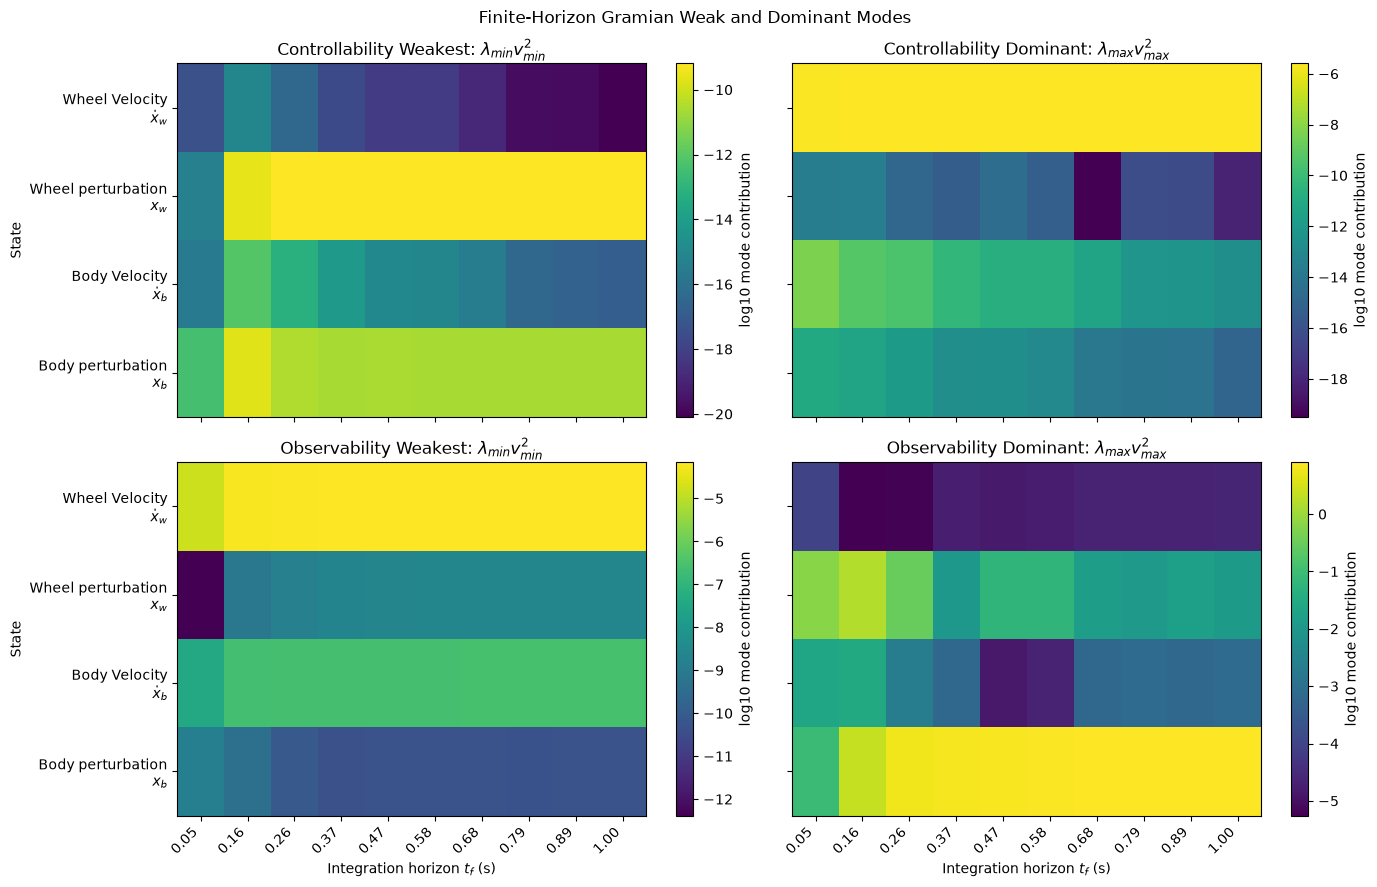

In [10]:
def plot_gramian_mode_grid(time_horizons, mode_impacts):
    tiny = np.finfo(np.float64).tiny
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

    for axis, (title, state_impact) in zip(axes.ravel(), mode_impacts, strict=True):
        log_impact = np.log10(np.clip(state_impact.T, tiny, None))
        image = axis.imshow(log_impact, aspect="auto", origin="lower")
        axis.set_title(title)
        axis.set_xticks(np.arange(len(time_horizons)))
        axis.set_xticklabels(
            [f"{horizon:.2f}" for horizon in time_horizons],
            rotation=45,
            ha="right",
        )
        axis.set_yticks(np.arange(len(STATE_LABELS)))
        axis.set_yticklabels(STATE_LABELS)
        axis.grid(False)
        fig.colorbar(image, ax=axis, label="log10 mode contribution")

    for axis in axes[-1, :]:
        axis.set_xlabel("Integration horizon $t_f$ (s)")

    for axis in axes[:, 0]:
        axis.set_ylabel("State")

    fig.suptitle("Finite-Horizon Gramian Weak and Dominant Modes")
    plt.tight_layout()
    plt.show()


plot_gramian_mode_grid(
    time_horizons,
    [
        (
            r"Controllability Weakest: $\lambda_{min}v_{min}^2$",
            W_c_weakest_state_impact,
        ),
        (
            r"Controllability Dominant: $\lambda_{max}v_{max}^2$",
            W_c_dominant_state_impact,
        ),
        (
            r"Observability Weakest: $\lambda_{min}v_{min}^2$",
            W_o_weakest_state_impact,
        ),
        (
            r"Observability Dominant: $\lambda_{max}v_{max}^2$",
            W_o_dominant_state_impact,
        ),
    ],
)

<a id="part-3-static-weight-hinf-state-feedback"></a>
## Part 3 - Static-Weight H∞ State Feedback

The open-loop plant is stable, controllable from the actuator force, and observable from the selected suspension/body measurements. Stability alone does not tell us how well the suspension rejects road disturbance, so this section turns the physical ride objectives into a generalized H∞ state-feedback problem.

### H∞ State-Feedback Objective

Use the generalized continuous-time plant

$$
\dot{z}=Az+B_w w+B_u u,
$$

$$
z_p=C_pz+D_{pw}w+D_{pu}u.
$$

Here $w$ is the exogenous road input, $u$ is the active suspension force, and $z_p$ is the weighted performance output. For static full-state feedback, use the regulation error

$$
e=z-z_{ref}.
$$

In this first design $z_{ref}=0$, so $e=z$ and

$$
u=Ke=Kz.
$$

With that convention, the closed-loop map from road disturbance to performance output is

$$
\dot{z}=A_{cl}z+B_w w,
$$

$$
z_p=C_{cl}z+D_{pw}w,
$$

with

$$
A_{cl}=A+B_uK,
\qquad
C_{cl}=C_p+D_{pu}K.
$$

The H∞ objective is to find a stabilizing gain $K$ such that the induced $L_2$ gain from road disturbance $w$ to weighted performance $z_p$ is below a scalar bound $\gamma$:

$$
\lVert T_{w\rightarrow z_p}\rVert_\infty
=\sup_{w\ne 0}\frac{\lVert z_p\rVert_2}{\lVert w\rVert_2}<\gamma.
$$

### Bounded-Real Lemma Form

For the closed-loop realization $(A_{cl},B_w,C_{cl},D_{pw})$, the continuous-time bounded-real lemma states that $\lVert T_{w\rightarrow z_p}\rVert_\infty<\gamma$ if there exists $P=P^{\mathsf T}\succ0$ such that

$$
\begin{bmatrix}
A_{cl}^{\mathsf T}P+PA_{cl} & PB_w & C_{cl}^{\mathsf T} \\
B_w^{\mathsf T}P & -\gamma I & D_{pw}^{\mathsf T} \\
C_{cl} & D_{pw} & -\gamma I
\end{bmatrix}\prec0.
$$

This expression is not directly convex in $P$ and $K$ because $PA_{cl}$ and $C_{cl}$ contain products involving $P$ and $K$.

### Convex State-Feedback Change of Variables

Use the standard inverse-Lyapunov substitution

$$
Q=P^{-1},\qquad Y=KQ.
$$

After congruence transformation, the state-feedback H∞ LMI can be written as

$$
\begin{bmatrix}
AQ+QA^{\mathsf T}+B_uY+Y^{\mathsf T}B_u^{\mathsf T} & B_w & (C_pQ+D_{pu}Y)^{\mathsf T} \\
B_w^{\mathsf T} & -\gamma I & D_{pw}^{\mathsf T} \\
C_pQ+D_{pu}Y & D_{pw} & -\gamma I
\end{bmatrix}\prec0,
$$

with

$$
Q\succ0.
$$

The convex synthesis problem is therefore

$$
\begin{aligned}
\min_{Q,Y,\gamma}\quad & \gamma \\
\text{subject to}\quad & Q\succ0, \\
& \operatorname{BRL}(Q,Y,\gamma)\prec0.
\end{aligned}
$$

After solving the LMI, recover the state-feedback gain by

$$
K=YQ^{-1}.
$$


### Generalized Plant and Physical Performance Outputs

For the active quarter-car suspension, the first static design tracks four physical objectives:

1. **ride comfort**: reduce body acceleration,
2. **suspension travel**: keep $x_b-x_w$ within mechanical limits,
3. **road holding**: reduce tire deflection $x_w-r$,
4. **actuator effort**: penalize hydraulic-cylinder force.

The physical performance vector is

$$
q=\begin{bmatrix}
\ddot{x}_b & x_b-x_w & x_w-r & u
\end{bmatrix}^{\mathsf T}.
$$

Static weighting then forms

$$
z_p=W_q q.
$$

We use one notation convention throughout the rest of the notebook:

- $C_q$ and $D_q$ map the plant variables to the **unweighted physical channels** $q$,
- $W_q$ is the static weighting matrix (and $W_q(s)$ will denote the dynamic weighting operator), and
- $C_p$ and $D_p$ map the chosen realization to the **weighted performance output** $z_p$.

For the static case these objects are related by

$$
v=\begin{bmatrix}w&u\end{bmatrix}^{\mathsf T},\qquad q=C_qz+D_qv,\qquad
z_p=W_q\,q=C_pz+D_pv,\qquad
C_p:=W_qC_q,\quad D_p:=W_qD_q.
$$

Thus $W_q$ and $C_p$ are related but not interchangeable: $W_q$ acts on physical outputs, whereas $C_p$ acts on the realization state.

The block diagram below expands the generalized plant $P$ instead of hiding everything inside one box. The H∞ synthesis still sees the bundled map from road disturbance and actuator force to weighted performance output, but the diagram exposes where each physical signal enters the weighting pattern.

```mermaid
flowchart LR
    d["r"] -->|"r"| Wr["W_r"]
    Wr -->|"w"| G["Plant"]
    u_sig(( )) -->|"u = f_c"| G

    G -->|"z"| branch(( ))
    branch -->|"z"| sumE(("Σ"))
    ref["z_ref = 0"] -->|"-z_ref"| sumE
    sumE -->|"e = z - z_ref"| K["K"]
    K -->|"u"| u_sig

    G -->|"ẍ_b"| Wa["W_a"]
    G -->|"x_b - x_w"| Ws["W_s"]
    G -->|"x_w - r"| Wt["W_t"]
    u_sig -->|"u"| Wu["W_u"]

    Wa -->|"z_a"| za["comfort"]
    Ws -->|"z_s"| zs["suspension travel"]
    Wt -->|"z_t"| zt["road holding"]
    Wu -->|"z_u"| zu["effort"]

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#111111,stroke-width:1.3px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class G,K,Wr,Wa,Ws,Wt,Wu block;
    class d,ref,za,zs,zt,zu signal;
    class sumE,branch,u_sig junction;
```

The road perturbation impacts the wheel through the tire, and the suspension transmits part of that motion into the body. The controller acts on the regulation error $e=z-z_{ref}$; with $z_{ref}=0$ this is the state perturbation itself. The actuator then trades body isolation, suspension stroke, tire contact, and force usage.

In the implementation below, the physical state, road input, actuator input, and performance channels are first scaled to order-one variables. The H∞ LMI is solved on that nondimensionalized generalized plant, then the returned scaled gain is transformed back into physical newtons.


In [11]:
performance_labels = [
    r"Body acceleration $\ddot{x}_b$ [m/s$^2$]",
    r"Suspension travel $x_b - x_w$ [m]",
    r"Tire deflection $x_w - r$ [m]",
    r"Actuator force $u$ [N]",
]

C_q = np.array(
    [A[1, :], [1.0, 0.0, -1.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 0.0]],
    dtype=np.float64,
)
D_q = np.array(
    [
        [B_w[1, 0], B_u[1, 0]],
        [0.0, 0.0],
        [-1.0, 0.0],
        [0.0, 1.0],
    ],
    dtype=np.float64,
)

performance_weighting_values = np.array(
    [3.0e-3, 1.0e-4, 1.0e-4, 1.0e-5],
    dtype=np.float64,
)
P_z = np.diag(performance_weighting_values)

print(f"C_q =\n{C_q}")
print(f"D_q =\n{D_q}")

C_q =
[[-88.88888889  -6.66666667  88.88888889   6.66666667]
 [  1.           0.          -1.           0.        ]
 [  0.           0.           1.           0.        ]
 [  0.           0.           0.           0.        ]]
D_q =
[[ 0.          0.00222222]
 [ 0.          0.        ]
 [-1.          0.        ]
 [ 0.          1.        ]]


### Nondimensionalization & Scaling

The diagonal scalings are applied to states, inputs, performance channels, and time to improve numerical conditioning of the semidefinite program. In this notebook the vehicle state is $z$, and the performance output is $z_p$.

Use barred variables for the scaled synthesis coordinates:

$$
z=S_z\bar{z},\qquad
\begin{bmatrix}r \\ u\end{bmatrix}=S_{in}\begin{bmatrix}\bar{w} \\ \bar{u}\end{bmatrix},\qquad
\bar{q}=S_{p}^{-1}q,\qquad z_p=P_z\bar q.
$$

Here $S_z$ scales the state, $S_p$ scales the physical performance channels, and $P_z$ sets their static priorities. The normalized generalized plant is

$$
\frac{d\bar{z}}{d\tau}
= T_{ref}S_z^{-1}AS_z\bar{z}
+ T_{ref}S_z^{-1}BS_{in}\begin{bmatrix}\bar{w} \\ \bar{u}\end{bmatrix},
$$

$$
z_p
= \underbrace{P_zS_p^{-1}C_qS_z}_{\bar C_p}\bar{z}
+ \underbrace{P_zS_p^{-1}D_qS_{in}}_{\bar D_p}\begin{bmatrix}\bar{w} \\ \bar{u}\end{bmatrix}.
$$

where $\tau=t/T_{ref}$ (i.e., normalized time-scale scaling the dynamic rates). If the solver returns $\bar{u}=\bar{K}\bar{z}$, the physical force gain is

$$
u=S_u\bar{K}S_z^{-1}z.
$$

In [12]:
state_scale_values = np.array(
    [0.05, 0.5, 0.05, 0.5], dtype=np.float64
)  # [m, m/s, m, m/s]
input_scale_values = np.array(
    [0.02, 10_000.0], dtype=np.float64
)  # [m road, N actuator]
performance_scale_values = np.array(
    [5.0, 0.10, 0.05, 10_100.0], dtype=np.float64
)  # [m/s^2, m, m, N]

S_z = np.diag(state_scale_values)
S_z_inv = np.diag(1.0 / state_scale_values)
S_in = np.diag(input_scale_values)
S_p_inv = np.diag(1.0 / performance_scale_values)

T_REF = 1e-4  # tau = t / T_REF

A_scaled = T_REF * (S_z_inv @ A @ S_z)
B_scaled = T_REF * (S_z_inv @ B @ S_in)
C_q_scaled = S_p_inv @ C_q @ S_z
D_q_scaled = S_p_inv @ D_q @ S_in

W_q = P_z @ S_p_inv
C_p_scaled = P_z @ C_q_scaled
D_p_scaled = P_z @ D_q_scaled

print(f"State scales [x_b, xdot_b, x_w, xdot_w]:\n{state_scale_values}")
print(f"Input scales [road r, actuator u]:\n{input_scale_values}")
print("Performance scales [body accel, travel, tire, actuator]:")
print(performance_scale_values)
print(f"Time scale T_REF: {T_REF:.1e} s")
print(f"max |A_scaled| = {np.max(np.abs(A_scaled)):.3g}")
print(f"max |B_scaled| = {np.max(np.abs(B_scaled)):.3g}")
print(f"max |C_q_scaled| = {np.max(np.abs(C_q_scaled)):.3g}")
print(f"max |D_q_scaled| = {np.max(np.abs(D_q_scaled)):.3g}")
print("Performance priorities:")
for label, priority in zip(
    performance_labels, performance_weighting_values, strict=True
):
    print(f" {label}: {priority:.3e}")
print(f"max |C_p_scaled| = {np.max(np.abs(C_p_scaled)):.3g}")
print(f"max |D_p_scaled| = {np.max(np.abs(D_p_scaled)):.3g}")

State scales [x_b, xdot_b, x_w, xdot_w]:
[0.05 0.5  0.05 0.5 ]
Input scales [road r, actuator u]:
[2.e-02 1.e+04]
Performance scales [body accel, travel, tire, actuator]:
[5.00e+00 1.00e-01 5.00e-02 1.01e+04]
Time scale T_REF: 1.0e-04 s
max |A_scaled| = 0.0369
max |B_scaled| = 0.0308
max |C_q_scaled| = 1
max |D_q_scaled| = 4.44
Performance priorities:
 Body acceleration $\ddot{x}_b$ [m/s$^2$]: 3.000e-03
 Suspension travel $x_b - x_w$ [m]: 1.000e-04
 Tire deflection $x_w - r$ [m]: 1.000e-04
 Actuator force $u$ [N]: 1.000e-05
max |C_p_scaled| = 0.00267
max |D_p_scaled| = 0.0133


In [13]:
hinf_feedback_result = controls.solve_hinf_state_feedback(
    A_scaled,
    B_scaled,
    C_p_scaled,
    D_p_scaled,
    exogenous_dim=1,
)

K_hinf_scaled = np.asarray(hinf_feedback_result.K, dtype=np.float64)
K_hinf = input_scale_values[1] * K_hinf_scaled @ S_z_inv
A_hinf_closed_loop = A + B_u @ K_hinf
hinf_closed_loop_poles = np.linalg.eigvals(A_hinf_closed_loop)

print(f"Solver status: {hinf_feedback_result.status}")
print(f"Solver event: {hinf_feedback_result.event}")
print(f"Iterations: {hinf_feedback_result.num_iter}")
print(f"gamma_K: {hinf_feedback_result.gamma:.6g}")
print(f"K_hinf scaled gain =\n{K_hinf_scaled}")
print(f"K_hinf physical force gain =\n{K_hinf}")
print(f"Closed-loop poles: {hinf_closed_loop_poles}")

Solver status: OPTIMAL
Solver event: NONE
Iterations: 14
gamma_K: 0.00570525
K_hinf scaled gain =
[[ 0.18695201  0.02622249 -0.19205736 -0.13743824]]
K_hinf physical force gain =
[[ 37390.40294397    524.44979998 -38411.47261516  -2748.7648868 ]]
Closed-loop poles: [-1.93904749+55.46461865j -1.93904749-55.46461865j
 -1.42612808 +0.j         -4.06215521 +0.j        ]


### Weighted Performance Realization and H∞ Norm

The H∞ certificate should be checked in the same coordinates used for synthesis. In this notebook, the state-feedback LMI is solved on the scaled generalized plant

$$
\frac{d\bar{z}}{d\tau}=\bar{A}\bar{z}+\bar{B}_w\bar{w}+\bar{B}_u\bar{u},
$$

$$
z_p=\bar{C}_p\bar{z}+\bar{D}_{pw}\bar{w}+\bar{D}_{pu}\bar{u}.
$$

The scaled feedback law is

$$
\bar{u}=\bar{K}\bar{z}.
$$

The closed-loop synthesis realization is

$$
\bar{A}_{cl}=\bar{A}+\bar{B}_u\bar{K},
\qquad
\bar{C}_{cl}=\bar{C}_p+\bar{D}_{pu}\bar{K},
\qquad
\bar{B}_{cl}=\bar{B}_w,
\qquad
\bar{D}_{cl}=\bar{D}_{pw}.
$$

Therefore, the nondimensionalized weighted-performance transfer function evaluated by the norm check is

$$
G_{\bar{w}\rightarrow z_p}(j\omega)
=\bar{C}_{cl}\left(j\omega I-\bar{A}_{cl}\right)^{-1}\bar{B}_{cl}
+\bar{D}_{cl}.
$$

The solver bound $\gamma_K$ applies directly to this normalized transfer function:

$$
\left\lVert G_{\bar{w}\rightarrow z_p}\right\rVert_\infty < \gamma_K.
$$

So the cleanest diagnostic is to evaluate $\bar{w}\rightarrow z_p$ on the scaled closed-loop realization and compare that value directly with $\gamma_K$.


In [14]:
def estimate_hinf_norm(A_cl, B_cl, C_cl, D_cl, frequencies):
    peak_gain = -np.inf
    peak_omega = np.nan
    I = np.eye(A_cl.shape[0])
    for omega in frequencies:
        response = C_cl @ np.linalg.solve(1j * omega * I - A_cl, B_cl) + D_cl
        gain = np.linalg.svd(response, compute_uv=False)[0]
        if gain > peak_gain:
            peak_gain = gain
            peak_omega = omega
    return peak_gain, peak_omega


scaled_frequency_grid = np.logspace(-5, -1, 2_000)
frequency_grid = np.logspace(-1, 3, 2_000)

B_scaled_w = B_scaled[:, [0]]
B_scaled_u = B_scaled[:, [1]]
D_scaled_pw = D_p_scaled[:, [0]]
D_scaled_pu = D_p_scaled[:, [1]]

passive_scaled_norm, passive_scaled_omega = estimate_hinf_norm(
    A_scaled,
    B_scaled_w,
    C_p_scaled,
    D_scaled_pw,
    scaled_frequency_grid,
)

A_scaled_closed = A_scaled + B_scaled_u @ K_hinf_scaled
B_scaled_closed = B_scaled_w
C_p_scaled_closed = C_p_scaled + D_scaled_pu @ K_hinf_scaled
D_scaled_closed = D_scaled_pw
active_scaled_norm, active_scaled_omega = estimate_hinf_norm(
    A_scaled_closed,
    B_scaled_closed,
    C_p_scaled_closed,
    D_scaled_closed,
    scaled_frequency_grid,
)

active_bounded = active_scaled_norm <= hinf_feedback_result.gamma
passive_bounded = passive_scaled_norm <= hinf_feedback_result.gamma

print(f"Solver gamma_K: {hinf_feedback_result.gamma:.6g}")
print(
    "Passive normalized ||w_bar -> z_p||_inf: "
    f"{passive_scaled_norm:.6g} at {passive_scaled_omega:.3e} rad/tau"
)
print(f"Passive bounded by gamma_K? {passive_bounded}")
print(
    "Active normalized ||w_bar -> z_p||_inf: "
    f"{active_scaled_norm:.6g} at {active_scaled_omega:.3e} rad/tau"
)
print(f"Active bounded by gamma_K? {active_bounded}")
active_margin = hinf_feedback_result.gamma - active_scaled_norm
print(f"Active margin gamma_K - norm: {active_margin:.3e}")

Solver gamma_K: 0.00570525
Passive normalized ||w_bar -> z_p||_inf: 0.00536513 at 5.799e-03 rad/tau
Passive bounded by gamma_K? True
Active normalized ||w_bar -> z_p||_inf: 0.00536276 at 5.538e-03 rad/tau
Active bounded by gamma_K? True
Active margin gamma_K - norm: 3.425e-04


<a id="part-4-hinf-observer-output-feedback"></a>
## Part 4 - H∞ Observer and Static-Weight Output Feedback

The Part 3 gain assumes full-state feedback. Now synthesize an observer so the same static H∞ gain can run from the measured output

$$
y=C_yz+n,
\qquad
C_y=\begin{bmatrix}1&0&-1&0\\0&1&0&0\end{bmatrix},
$$

or

$$
y=\begin{bmatrix}x_b-x_w \\ \dot{x}_b\end{bmatrix}
+\begin{bmatrix}n_s \\ n_v\end{bmatrix}.
$$

The measured signals are not the H∞ performance output. They are the signals used to reconstruct the full state $z$. The observer generalized plant exposes the road disturbance and both sensor-noise channels explicitly:

```mermaid
flowchart LR
    r["r"] -->|"road input"| G["Plant"]
    G -->|"z"| Cy["C_y"]
    Cy -->|"C_y z"| sumY(("Σ"))
    n["n = [n_s, n_v]ᵀ"] -->|"sensor noise"| sumY
    sumY -->|"y = C_y z + n"| Obs["H∞ observer<br/>ν = y - C_y ẑ<br/>correction: Lν"]
    Obs -->|"ẑ"| K["K"]
    K -->|"u = Kẑ"| G

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#111111,stroke-width:1.3px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class G,Cy,Obs,K block;
    class r,n signal;
    class sumY junction;
```

Here $r$ changes the physical state through the tire force. The noise channels do not act on the suspension dynamics; they corrupt the two components of $y$ before the innovation reaches the observer. Together, $d=[r,\,n_s,\,n_v]^{\mathsf T}$ forms the exogenous input used for observer synthesis.

### H∞ Observer Objective

Let

$$
e_z=z-\hat z,
\qquad
d=\begin{bmatrix}r \\ n_s \\ n_v\end{bmatrix}.
$$

The road input enters the plant dynamics, and sensor noise enters the measurement directly:

$$
B_d=\begin{bmatrix}B_w & 0 & 0\end{bmatrix},
\qquad
D_{yd}=\begin{bmatrix}0&1&0\\0&0&1\end{bmatrix}.
$$

For the observer design,

$$
\dot z=Az+B_u u+B_d d,
\qquad
y=C_yz+D_{yd}d,
$$

and

$$
\dot{\hat z}=A\hat z+B_u u+L(y-C_y\hat z).
$$

Substituting $y$ and subtracting gives

$$
\begin{aligned}
\dot e_z
&=\dot z-\dot{\hat z}\\
&=(A-LC_y)(z-\hat z)+(B_d-LD_{yd})d,
\end{aligned}
$$

so

$$
\dot e_z=(A-LC_y)e_z+(B_d-LD_{yd})d.
$$

For the unweighted error output, the transfer from disturbance/noise to estimation error is

$$
T_{d\rightarrow e_z}(s)
=\left(sI-(A-LC_y)\right)^{-1}(B_d-LD_{yd}).
$$

The observer solve minimizes the worst-case reconstruction gain:

$$
\min_L\ \left\lVert T_{d\rightarrow e_z}\right\rVert_\infty < \gamma_L.
$$

### Observer Scaling and Generalized Plant

The code below builds the scaled observer plant. Disturbance channels are normalized by representative signal magnitudes. The sensor-noise scales are used like one-sigma noise levels for the tutorial, but the H∞ objective remains deterministic worst-case gain analysis.

The observer performance channel is a small weighted estimation error:

$$
\bar e=10^{-4}\bar e_z.
$$


In [15]:
# Observer synthesis disturbance model:
# d = [road, suspension-travel noise, body-velocity noise].
B_obs_disturbance = np.hstack((B_w, np.zeros((A.shape[0], 2), dtype=np.float64)))
D_meas_disturbance = np.array(
    [
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0],
    ],
    dtype=np.float64,
)

obs_disturbance_scale_values = np.array(
    [0.05, 0.005, 0.05],
    dtype=np.float64,
)  # [m road, m suspension-travel noise, m/s body-velocity noise]
meas_scale_values = np.array([0.10, 0.50], dtype=np.float64)  # [m, m/s]

S_obs_disturbance = np.diag(obs_disturbance_scale_values)
S_y = np.diag(meas_scale_values)
S_y_inv = np.diag(1.0 / meas_scale_values)

T_OBS_REF = 1.0e-2
obs_error_scale = 1.0e-4

A_obs_scaled = T_OBS_REF * (S_z_inv @ A @ S_z)
B_obs_scaled = T_OBS_REF * (S_z_inv @ B_obs_disturbance @ S_obs_disturbance)
C_error_scaled = obs_error_scale * np.eye(A.shape[0], dtype=np.float64)
D_error_scaled = np.zeros(
    (A.shape[0], B_obs_disturbance.shape[1]),
    dtype=np.float64,
)
C_meas_scaled = S_y_inv @ C_y @ S_z
D_meas_scaled = S_y_inv @ D_meas_disturbance @ S_obs_disturbance
C_obs_scaled = np.vstack((C_error_scaled, C_meas_scaled))
D_obs_scaled = np.vstack((D_error_scaled, D_meas_scaled))

print("Measurement channels:")
for label, scale, unit in zip(
    MEASUREMENT_LABELS, meas_scale_values, MEASUREMENT_UNITS, strict=True
):
    print(f"  {label}: scale = {scale:.3g} {unit}")
print(f"max |A_obs_scaled| = {np.max(np.abs(A_obs_scaled)):.3g}")
print(f"max |B_obs_scaled| = {np.max(np.abs(B_obs_scaled)):.3g}")
print(f"max |C_obs_scaled| = {np.max(np.abs(C_obs_scaled)):.3g}")
print(f"max |D_obs_scaled| = {np.max(np.abs(D_obs_scaled)):.3g}")

Measurement channels:
  Suspension travel $x_b-x_w$: scale = 0.1 m
  Body velocity $\dot{x}_b$: scale = 0.5 m/s
max |A_obs_scaled| = 3.69
max |B_obs_scaled| = 3.08
max |C_obs_scaled| = 1
max |D_obs_scaled| = 0.1


### Scaled H∞ Observer Synthesis

The solver returns the scaled observer gain $\bar L$. Since this gain multiplies a measurement residual inside a time derivative, the physical-time recovery includes the observer time scale:

$$
\bar L = T_{obs} S_{z}^{-1} L S_y \to L = \frac{1}{T_{obs}} S_z \bar L S_y^{-1}.
$$

The poles reported below are the estimator-error poles of $A-LC_y$.


In [16]:
hinf_obs_result = controls.solve_hinf_state_observer(
    A_obs_scaled,
    B_obs_scaled,
    C_obs_scaled,
    D_obs_scaled,
    performance_dim=4,
)

L_hinf_scaled = np.asarray(hinf_obs_result.L, dtype=np.float64)
L_hinf = (1.0 / T_OBS_REF) * S_z @ L_hinf_scaled @ S_y_inv
obs_poles = np.linalg.eigvals(A - L_hinf @ C_y)

print(f"Observer solver status: {hinf_obs_result.status}")
print(f"Observer solver event: {hinf_obs_result.event}")
print(f"Observer iterations: {hinf_obs_result.num_iter}")
print(f"Observer gamma_L: {hinf_obs_result.gamma:.6g}")
print(f"L_hinf scaled gain =\n{L_hinf_scaled}")
print(f"L_hinf physical gain =\n{L_hinf}")
print(f"Observer poles: {obs_poles}")

Observer solver status: OPTIMAL
Observer solver event: NONE
Observer iterations: 13
Observer gamma_L: 0.000166766
L_hinf scaled gain =
[[   7.30512373   -2.32974145]
 [ -25.24801509    8.44251122]
 [ -30.64140742   10.24955592]
 [-621.92627502  205.6512739 ]]
L_hinf physical gain =
[[ 3.65256187e+02 -2.32974145e+01]
 [-1.26240075e+04  8.44251122e+02]
 [-1.53207037e+03  1.02495559e+02]
 [-3.10963138e+05  2.05651274e+04]]
Observer poles: [-2559.72166721+0.j  -222.72455059+0.j    -2.86179585+0.j
    -9.09017826+0.j]


### Observer Error Realization and H∞ Norm

Check the observer certificate in the same scaled coordinates used by the solver:

$$
\bar A_e=\bar A-\bar L\bar C_y,
\qquad
\bar B_e=\bar B_d-\bar L\bar D_{yd},
$$

$$
\left\lVert T_{\bar d\rightarrow\bar e}\right\rVert_\infty < \gamma_L.
$$

This certifies the observer-error subproblem only. The plant plus observer-based compensator is validated separately.


In [17]:
A_obs_error_scaled = A_obs_scaled - L_hinf_scaled @ C_meas_scaled
B_obs_error_scaled = B_obs_scaled - L_hinf_scaled @ D_meas_scaled
C_obs_error_scaled = C_error_scaled
D_obs_error_scaled = D_error_scaled

obs_norm_grid = np.logspace(-6, 3, 4_000)
obs_error_peak, obs_error_peak_frequency = estimate_hinf_norm(
    A_obs_error_scaled,
    B_obs_error_scaled,
    C_obs_error_scaled,
    D_obs_error_scaled,
    obs_norm_grid,
)
obs_error_bounded = obs_error_peak <= hinf_obs_result.gamma * (1.0 + 1e-2)

print(
    "Observer estimated ||d_bar -> e_bar||_inf: "
    f"{obs_error_peak:.6g} at {obs_error_peak_frequency:.3g} rad/tau_obs"
)
print(f"Observer solver gamma_L: {hinf_obs_result.gamma:.6g}")
print(f"Observer norm bounded by gamma_L? {obs_error_bounded}")

Observer estimated ||d_bar -> e_bar||_inf: 0.00015079 at 1e-06 rad/tau_obs
Observer solver gamma_L: 0.000166766
Observer norm bounded by gamma_L? True


### Dynamic Compensator

Use the observer state in the static H∞ force law:

$$
u=K\hat z.
$$

The plant dynamics under this estimated-state feedback are

$$
\dot z=Az+B_uK\hat z+B_w r.
$$

The measurement is

$$
y=C_yz+\begin{bmatrix}n_s\\n_v\end{bmatrix},
$$

so the observer dynamics become

$$
\begin{aligned}
\dot{\hat z}
&=(A+B_uK-LC_y)\hat z+Ly\\
&=LC_yz+(A+B_uK-LC_y)\hat z
+L\begin{bmatrix}n_s\\n_v\end{bmatrix}.
\end{aligned}
$$

Packing those two equations together gives the plant-compensator interconnection

$$
\begin{bmatrix}
\dot z\\
\dot{\hat z}
\end{bmatrix}
=
\underbrace{\begin{bmatrix}
A & B_uK\\
LC_y & A+B_uK-LC_y
\end{bmatrix}}_{A_{of}}
\begin{bmatrix}
z\\
\hat z
\end{bmatrix}
+
\underbrace{\begin{bmatrix}
B_w & 0 & 0\\
0 & L
\end{bmatrix}}_{B_{of}}
\begin{bmatrix}
r\\
n_s\\
n_v
\end{bmatrix}.
$$

The next cells inspect the compensator realization and then the full plant-compensator interconnection.


In [18]:
A_compensator = A + B_u @ K_hinf - L_hinf @ C_y
B_compensator = L_hinf
C_compensator = K_hinf
D_compensator = np.zeros((1, C_y.shape[0]), dtype=np.float64)

compensator_poles = np.linalg.eigvals(A_compensator)

print(f"Standalone compensator poles: {compensator_poles}")
print(f"A_compensator =\n{A_compensator}")
print(f"B_compensator =\n{B_compensator}")
print(f"C_compensator =\n{C_compensator}")

Standalone compensator poles: [-2.61922126e+03+0.j -9.94013730e+01+0.j -1.41216065e+00+0.j
 -3.09092631e+01+0.j]
A_compensator =
[[-3.65256187e+02  2.42974145e+01  3.65256187e+02  0.00000000e+00]
 [ 1.26182084e+04 -8.49752344e+02 -1.26204775e+04  5.58300252e-01]
 [ 1.53207037e+03 -1.02495559e+02 -1.53207037e+03  1.00000000e+00]
 [ 3.11003285e+05 -2.05270420e+04 -3.14064499e+05 -3.86515559e+00]]
B_compensator =
[[ 3.65256187e+02 -2.32974145e+01]
 [-1.26240075e+04  8.44251122e+02]
 [-1.53207037e+03  1.02495559e+02]
 [-3.10963138e+05  2.05651274e+04]]
C_compensator =
[[ 37390.40294397    524.44979998 -38411.47261516  -2748.7648868 ]]


### Plant and Compensator Interconnection

$K$ and $L$ were synthesized as separate H∞ subproblems, so there is no single inherited $\gamma$ for the combined compensator. The practical checks are therefore:

1. poles of the full plant-compensator interconnection,
2. achieved norm from $[r,n_s,n_v]$ to the static weighted performance output.

Before forming this interconnection, both gains are pulled back from their synthesis coordinates:

$$
K=S_u\bar K S_z^{-1},
\qquad
L=\frac{1}{T_{obs}}S_z\bar L S_y^{-1}.
$$

Therefore $A_{of}$, $B_{of}$, and the frequency grid below are in physical state, input, and time coordinates. For the H∞ analysis, only the external channels are normalized and weighted:

$$
d=S_d\bar d,
\qquad
z_p=W_q q,
\qquad
W_q=P_zS_p^{-1}.
$$

Following the Part 3 convention, $C_{p,of}:=W_qC_{q,of}$ and $D_{p,of}:=W_qD_{q,of}$. Substitution gives $B_{of}S_d$, $C_{p,of}$, and $D_{p,of}S_d$. Thus the computed norm is $\lVert T_{\bar d\rightarrow z_p}\rVert_\infty$. Physical performance can be recovered with $q=S_pP_z^{-1}z_p$.


In [19]:
def observer_based_closed_loop(K, L):
    n = A.shape[0]
    A_cl = np.block(
        [
            [A, B_u @ K],
            [L @ C_y, A + B_u @ K - L @ C_y],
        ]
    )
    B_cl = np.block(
        [
            [B_w, np.zeros((n, 2), dtype=np.float64)],
            [np.zeros((n, 1), dtype=np.float64), L],
        ]
    )
    C_q_cl = np.vstack(
        (
            np.hstack((A[1, :], B_u[1, 0] * K.ravel())),
            np.hstack(([1.0, 0.0, -1.0, 0.0], np.zeros(n))),
            np.hstack(([0.0, 0.0, 1.0, 0.0], np.zeros(n))),
            np.hstack((np.zeros(n), K.ravel())),
        )
    )
    D_q_cl = np.array(
        [
            [0.0, 0.0, 0.0],
            [0.0, 0.0, 0.0],
            [-1.0, 0.0, 0.0],
            [0.0, 0.0, 0.0],
        ],
        dtype=np.float64,
    )
    return A_cl, B_cl, C_q_cl, D_q_cl


A_of, B_of, C_q_of, D_q_of = observer_based_closed_loop(K_hinf, L_hinf)
observer_based_poles = np.linalg.eigvals(A_of)

C_p_of = W_q @ C_q_of
D_p_of = W_q @ D_q_of
observer_based_peak, observer_based_peak_frequency = estimate_hinf_norm(
    A_of,
    B_of @ S_obs_disturbance,
    C_p_of,
    D_p_of @ S_obs_disturbance,
    frequency_grid,
)

print(f"Closed-loop plant + compensator poles: {observer_based_poles}")
print(f"Max closed-loop pole real part: {np.max(np.real(observer_based_poles)):.6g}")
print(
    "Observer-based estimated ||[r_bar,n_s_bar,n_v_bar] -> z_p||_inf: "
    f"{observer_based_peak:.6g} at {observer_based_peak_frequency:.3f} rad/s"
)

Closed-loop plant + compensator poles: [-2.55972167e+03 +0.j         -2.22724551e+02 +0.j
 -1.93904749e+00+55.46461865j -1.93904749e+00-55.46461865j
 -1.42612808e+00 +0.j         -2.86179585e+00 +0.j
 -4.06215521e+00 +0.j         -9.09017826e+00 +0.j        ]
Max closed-loop pole real part: -1.42613
Observer-based estimated ||[r_bar,n_s_bar,n_v_bar] -> z_p||_inf: 0.0133835 at 55.638 rad/s


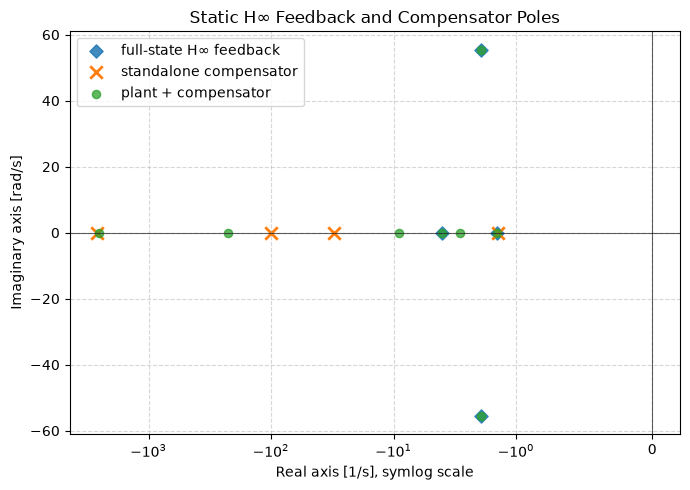

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.axvline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.scatter(
    np.real(hinf_closed_loop_poles),
    np.imag(hinf_closed_loop_poles),
    marker="D",
    s=45,
    alpha=0.85,
    label="full-state H∞ feedback",
)
ax.scatter(
    np.real(compensator_poles),
    np.imag(compensator_poles),
    marker="x",
    s=80,
    linewidths=2.0,
    label="standalone compensator",
)
ax.scatter(
    np.real(observer_based_poles),
    np.imag(observer_based_poles),
    marker="o",
    s=35,
    alpha=0.75,
    label="plant + compensator",
)
ax.set_title("Static H∞ Feedback and Compensator Poles")
ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_xlabel("Real axis [1/s], symlog scale")
ax.set_ylabel("Imaginary axis [rad/s]")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

<a id="part-5-frequency-shaped-hinf"></a>
## Part 5 - Frequency-Shaped H∞ Performance and Measured-Output Compensator

So far $K$ and $L$ have been synthesized using static performance weights for ride comfort, suspension travel, road holding, and actuator effort. This next part shapes the performance channels dynamically as a function of frequency. The notation from Part 3 remains unchanged: $C_q,D_q$ produce the physical channels $q$, $W_q(s)$ weights them, and $C_{p,\mathrm{aug}},D_{p,\mathrm{aug}}$ realize the resulting weighted output $z_p$ on the augmented state.

The following is the design process
1. analyze the passive and static H∞ frequency responses
1. design and plot the first order weights
1. augment and scale the generalized plant
1. synthesize and certify the dynamically weighted state feedback
1. form the dynamic compensator and compare the physical responses



### Baseline Physical Bode Responses

Lets start with the physical road disturbance to performance channel responses $r\rightarrow q_i$. The magnitude is the output to road amplitude ratio of the transfer function as evaluated by the frequency sweep, and the phase indicates whether the response leads or lags the road input. 

The bode plot below guide the first-order lead/lag weights below: the pole-zero placement changes both the gain applied across frequency and the phase through the transition region. For each physical channel we will evaluate

$$
T_{r\rightarrow q_i}(s)=C_{q_i,cl}(sI-A_{cl})^{-1}B_{r,cl}+D_{q_ir,cl}.
$$

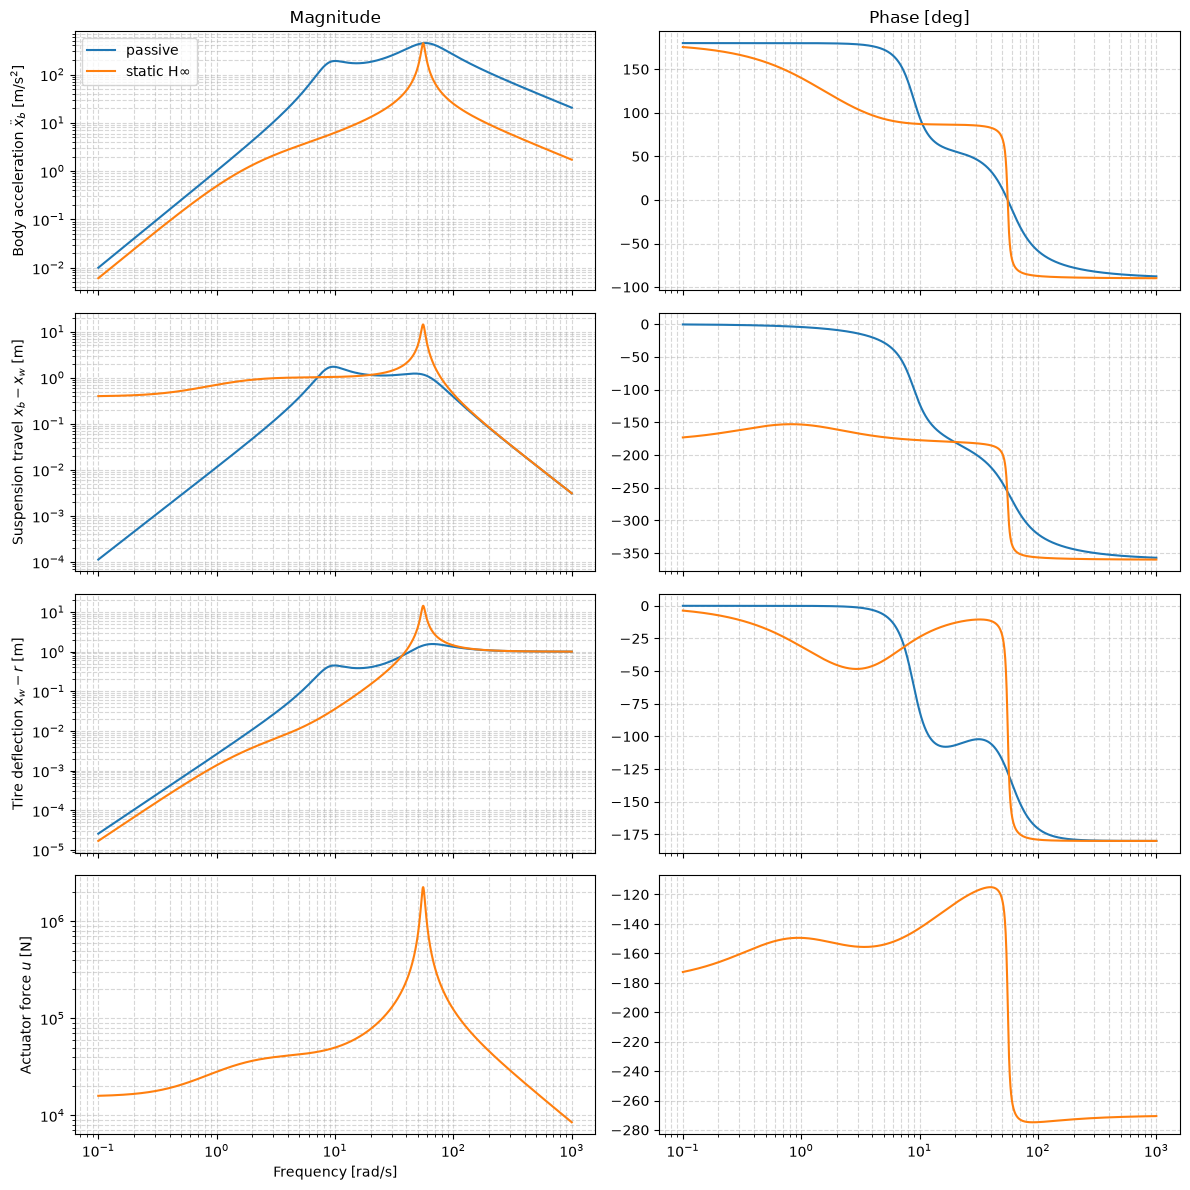

Body acceleration body motion peak: 10.023 rad/s
Suspension travel body motion peak: 9.660 rad/s
Actuator effort wheel hop peak: 55.382 rad/s


In [21]:
def channel_frequency_response(A_cl, B_cl, C_cl, D_cl, frequencies):
    I = np.eye(A_cl.shape[0])
    return np.array(
        [
            (C_cl @ np.linalg.solve(1j * omega * I - A_cl, B_cl) + D_cl).item()
            for omega in frequencies
        ],
        dtype=np.complex128,
    )


def peak_in_band(frequencies, response, omega_min, omega_max):
    magnitude = np.abs(response)
    mask = (frequencies >= omega_min) & (frequencies <= omega_max)
    band_indices = np.flatnonzero(mask)
    peak_index = band_indices[np.argmax(magnitude[mask])]
    return frequencies[peak_index], magnitude[peak_index]


A_static_hinf = A + B_u @ K_hinf
C_q_static_hinf = C_q + D_q[:, [1]] @ K_hinf
D_q_road = D_q[:, [0]]

baseline_channel_responses = {}
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)
for channel_index, label in enumerate(performance_labels):
    passive_response = channel_frequency_response(
        A, B_w, C_q[[channel_index], :], D_q_road[[channel_index], :], frequency_grid
    )
    static_response = channel_frequency_response(
        A_static_hinf,
        B_w,
        C_q_static_hinf[[channel_index], :],
        D_q_road[[channel_index], :],
        frequency_grid,
    )
    baseline_channel_responses[channel_index] = {
        "passive": passive_response,
        "static_hinf": static_response,
    }

    passive_magnitude = np.abs(passive_response)
    passive_magnitude[passive_magnitude < 1e-14] = np.nan
    static_magnitude = np.abs(static_response)
    static_magnitude[static_magnitude < 1e-14] = np.nan

    axes[channel_index, 0].loglog(
        frequency_grid,
        passive_magnitude,
        label="passive",
    )
    axes[channel_index, 0].loglog(
        frequency_grid,
        static_magnitude,
        label="static H∞",
    )

    passive_phase = np.degrees(np.unwrap(np.angle(passive_response)))
    passive_phase[np.abs(passive_response) < 1e-14] = np.nan
    static_phase = np.degrees(np.unwrap(np.angle(static_response)))
    static_phase[np.abs(static_response) < 1e-14] = np.nan
    axes[channel_index, 1].semilogx(frequency_grid, passive_phase, label="passive")
    axes[channel_index, 1].semilogx(frequency_grid, static_phase, label="static H∞")

    axes[channel_index, 0].set_ylabel(label)
    axes[channel_index, 0].grid(True, which="both", linestyle="--", alpha=0.5)
    axes[channel_index, 1].grid(True, which="both", linestyle="--", alpha=0.5)

axes[0, 0].set_title("Magnitude")
axes[0, 1].set_title("Phase [deg]")
axes[-1, 0].set_xlabel("Frequency [rad/s]")
axes[-1, 0].set_xlabel("Frequency [rad/s]")
axes[0, 0].legend(loc="best")
plt.tight_layout()
plt.show()

body_acceleration_peak, _ = peak_in_band(
    frequency_grid, baseline_channel_responses[0]["passive"], 0.0, 20.0
)
suspension_travel_peak, _ = peak_in_band(
    frequency_grid, baseline_channel_responses[1]["passive"], 0.0, 20.0
)
actuator_effort_peak, _ = peak_in_band(
    frequency_grid, baseline_channel_responses[3]["static_hinf"], 20.0, 150.0
)

print(f"Body acceleration body motion peak: {body_acceleration_peak:.3f} rad/s")
print(f"Suspension travel body motion peak: {suspension_travel_peak:.3f} rad/s")
print(f"Actuator effort wheel hop peak: {actuator_effort_peak:.3f} rad/s")

### First-Order Weight Design

Consider a proper first-order SISO weight written in lead-lag form with no time delay

$$
W_i(s) = G_\infty\frac{s + \omega_z}{s + \omega_p}
$$

where its low and high frequency gains are

$$
W_i(0) = G_\infty\frac{\omega_z}{\omega_p} = G_0,\qquad
W_i(\infty) = G_\infty.
$$

The first-order weighting filter behaves as either a lead or lag action depending on the relative pole and zero locations:

- **Lead action:** $\omega_z < \omega_p$. The zero acts first, producing positive phase lead through the transition band.
- **Lag action:** $\omega_z > \omega_p$. The pole acts first, producing phase lag and additional attenuation through the transition band.

The asymptotic shelf gains determine which frequency range is emphasized by the optimization:

- $G_0 > G_\infty$ places greater emphasis on low-frequency performance, encouraging the controller to reduce low-frequency gain in the associated physical channel.
- $G_\infty > G_0$ places greater emphasis on high-frequency performance, encouraging attenuation in the higher-frequency band.

Together, the pole-zero locations determine **where** the transition occurs, while the shelf gains determine **which side of the transition is weighted more heavily**.

Using $\omega_c = \omega_p$ leads to the gain shelf parameterization

$$
W_i(s) = \frac{G_\infty s + G_0 \omega_c}{s + \omega_c} = G_\infty\frac{s + (G_0/ G_\infty) \omega_c}{s + \omega_c}. 
$$

Therefore $-w_c$ is the pole and $-(G_0/G_\infty)\omega_c$ is the zero. Note that the gain does not switch instantaneously at $\omega_c$, it transitions smoothly across the pole-zero region. 

In this tutorial the respective cutoffs for suspension travel and control effort are placed slightly below their peaks s.t. the transition is already taking place as the corresponding mode is approached. Then to this end, body acceleration and suspension travel are penalized at lower frequencies, and conversely the actuator is penalized more at higher frequencies.

Lastly, in this tutorial the tire deflection has been left alone to be statically weighted due to the unmeasured road disturbance. We could estimate or perhaps preview the road with a Lidar scan, but this is out of scope for this series.


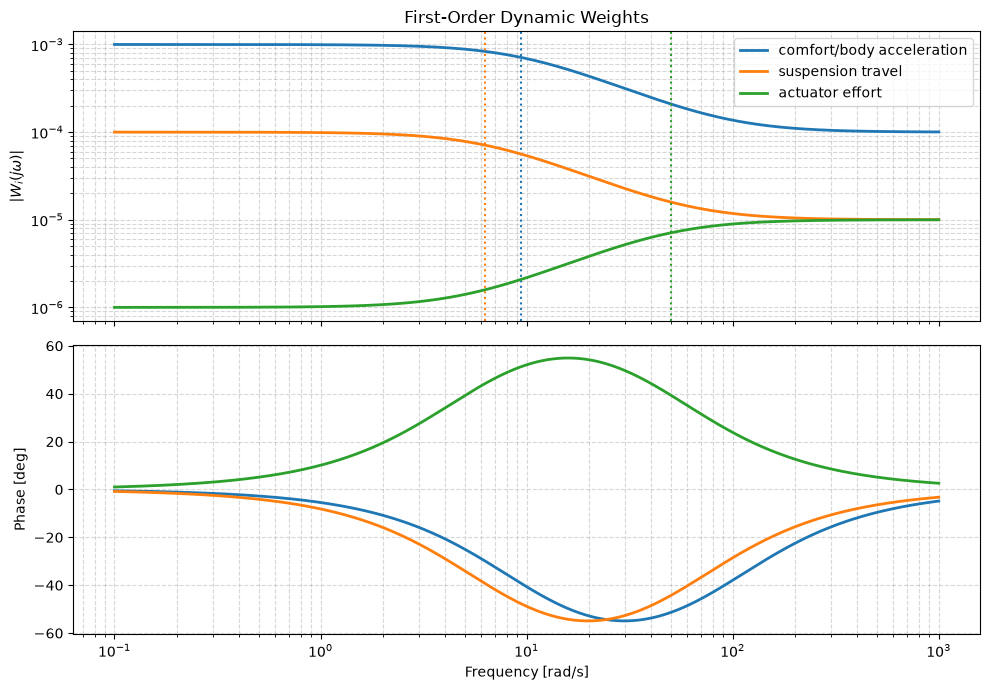

In [22]:
def lead_lag_response(G_0, G_inf, omega_c, frequencies):
    s = 1j * frequencies
    return (G_inf * s + G_0 * omega_c) / (s + omega_c)


DYNAMIC_WEIGHT_CHANNELS = [
    {
        "name": "comfort/body acceleration",
        "q_index": 0,
        "G_0": 1e-3,
        "G_inf": 1e-4,
        "omega_c": 2.0 * np.pi * 1.5,  # ~ 10 rad/s xddot peak
    },
    {
        "name": "suspension travel",
        "q_index": 1,
        "G_0": 1e-4,
        "G_inf": 1e-5,
        "omega_c": 2.0 * np.pi,  # < 10 rad/s (xb - xw) peak
    },
    {
        "name": "actuator effort",
        "q_index": 3,
        "G_0": 1e-6,
        "G_inf": 1e-5,
        "omega_c": 2.0 * np.pi * 8.0,  # < 59 rad/s u peak
    },
]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for channel in DYNAMIC_WEIGHT_CHANNELS:
    response = lead_lag_response(
        channel["G_0"],
        channel["G_inf"],
        channel["omega_c"],
        frequency_grid,
    )
    line = axes[0].loglog(
        frequency_grid,
        np.abs(response),
        linewidth=2.0,
        label=channel["name"],
    )[0]
    axes[0].axvline(
        channel["omega_c"],
        color=line.get_color(),
        linestyle=":",
        alpha=1.0,
    )
    axes[1].semilogx(
        frequency_grid,
        np.degrees(np.unwrap(np.angle(response))),
        linewidth=2.0,
        label=channel["name"],
    )

axes[0].set_title("First-Order Dynamic Weights")
axes[0].set_ylabel(r"$|W_i(j\omega)|$")
axes[1].set_ylabel("Phase [deg]")
axes[1].set_xlabel("Frequency [rad/s]")
for ax in axes:
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
axes[0].legend(loc="best")
plt.tight_layout()
plt.show()

### Augmented Generalized Plant

To form the augmented plant, we first require a state-space realization of the first-order weighting filter

$$
W_i(s)=\frac{G_{\infty,i}s+G_{0,i}\omega_{c,i}}
{s+\omega_{c,i}}.
$$

The weighted performance signal is defined as

$$
z_{W_i}(s)=W_i(s)q_i(s),
$$

where $q_i$ assumes the same performance channel outlined above. Our goal is therefore to realize the transfer function from $q_i \to z_{W_i}$ in state space form so that the filter dynamics can be appended to the generalized plant.

Rewriting the numerator gives

$$
G_{\infty,i}s+G_{0,i}\omega_{c,i}
=
G_{\infty,i}(s+\omega_{c,i})
+
(G_{0,i}-G_{\infty,i})\omega_{c,i},
$$

thus 

$$
W_i(s)
=
G_{\infty,i}
+
(G_{0,i}-G_{\infty,i})
\frac{\omega_{c,i}}{s+\omega_{c,i}}.
$$

The transfer function has naturally separated into a direct path and a first-order dynamic path. Lets now introduce the filter state

$$
x_{W_i}(s)
=
\frac{\omega_{c,i}}
{s+\omega_{c,i}}
q_i(s),
$$

which represents the dynamic component of the weighting filter.

To move from s-domain to time lets apply the inverse Laplace transform,

$$
X_{W_i}(s)
=
\frac{\omega_{c,i}}
{s+\omega_{c,i}}
Q_i(s),
$$

$$
(s+\omega_{c,i})X_{W_i}(s)
=
\omega_{c,i}Q_i(s),
$$

$$
sX_{W_i}(s)
+
\omega_{c,i}X_{W_i}(s)
=
\omega_{c,i}Q_i(s),
$$

where

$$
\mathcal{L}\{\dot{x}_{W_i}(t)\}
=
sX_{W_i}(s)-x_{W_i}(0),
\qquad
x_{W_i}(0)=0.
$$

and the filter state dynamics in the time domain can be written as

$$
\begin{align*}
\dot{x}_{W_i}
+
\omega_{c,i}x_{W_i}
=
\omega_{c,i}q_i\\

\underline{
\dot{x}_{W_i}
=
-\omega_{c,i}x_{W_i}
+
\omega_{c,i}q_i.
}
\end{align*}
$$

Finally, substituting the filter-state definition back into

$$
z_{W_i}(s)
=
W_i(s)q_i(s)
$$

yields

$$
Z_{W_i}(s)
=
(G_{0,i}-G_{\infty,i})X_{W_i}(s)
+
G_{\infty,i}Q_i(s),
$$

and applying a similar sequence as the filter state dynamics we arrive at the performance output

$$
\underline{
z_{W_i}
=
(G_{0,i}-G_{\infty,i})x_{W_i}
+
G_{\infty,i}q_i.
}
$$

The weighting filter has therefore been realized as a single augmented state. The state $x_{W_i}$ captures the dynamic (low-pass) component of the filter, while the direct term $G_{\infty,i}q_i$ captures the instantaneous high-frequency path. Appending these filter states to the physical plant allows the $H_\infty$ synthesis to optimize the weighted performance variables while leaving the physical dynamics unchanged.

So now collect the physical inputs as

$$
v=\begin{bmatrix}r & u\end{bmatrix}^{\mathsf T},
$$

giving the quarter-car realization

$$
\dot{z}=Az+B_vv,
\qquad
q=C_qz+D_qv,
\qquad
B_v=
\begin{bmatrix}
B_w & B_u
\end{bmatrix}.
$$

The weighting filters are driven by the physical performance outputs $q$. Appending the filter dynamics therefore augments the physical state with the filter states

$$
z_{\mathrm{aug}}
=
\begin{bmatrix}
z^{\mathsf T} &
x_{W_a} &
x_{W_s} &
x_{W_u}
\end{bmatrix}^{\mathsf T}.
$$

Writing the filter bank as

$$
\dot{x}_W=A_Wx_W+B_Wq,
\qquad
z_p=C_Wx_W+D_Wq,\\
\dot{x}_W=A_Wx_W+B_W(C_qz+D_qv),\qquad
z_p=C_Wx_W+D_W(C_qz+D_qv)
$$

This filter bank is the state-space realization of the dynamic weighting operator $W_q(s)$. Interconnecting it with the quarter-car dynamics yields the generalized augmented plant

$$
\begin{aligned}
A_{\mathrm{aug}}
&=
\begin{bmatrix}
A & 0\\
B_WC_q & A_W
\end{bmatrix},
&
B_{\mathrm{aug}}
&=
\begin{bmatrix}
B_v\\
B_WD_q
\end{bmatrix},
\\
C_{p,\mathrm{aug}}
&=
\begin{bmatrix}
D_WC_q & C_W
\end{bmatrix},
&
D_{p,\mathrm{aug}}
&=
D_WD_q.
\end{aligned}
$$

In [23]:
def build_dynamic_weight_augmented_plant(
    A, B, C_q, D_q, dynamic_channels, static_tire_weight
):
    n = A.shape[0]
    m = B.shape[1]
    n_filters = len(dynamic_channels)
    n_aug = n + n_filters

    A_aug = np.zeros((n_aug, n_aug), dtype=np.float64)
    B_aug = np.zeros((n_aug, m), dtype=np.float64)
    C_p_aug = np.zeros((4, n_aug), dtype=np.float64)
    D_p_aug = np.zeros((4, m), dtype=np.float64)

    A_aug[:n, :n] = A
    B_aug[:n, :] = B

    output_row_to_filter = {0: 0, 1: 1, 3: 3}
    for filter_index, channel in enumerate(dynamic_channels):
        state_index = n + filter_index
        q_index = channel["q_index"]
        omega_c = channel["omega_c"]
        G_0 = channel["G_0"]
        G_inf = channel["G_inf"]
        output_index = output_row_to_filter[q_index]

        A_aug[state_index, :n] = omega_c * C_q[q_index, :]
        A_aug[state_index, state_index] = -omega_c
        B_aug[state_index, :] = omega_c * D_q[q_index, :]

        C_p_aug[output_index, :n] = G_inf * C_q[q_index, :]
        C_p_aug[output_index, state_index] = G_0 - G_inf
        D_p_aug[output_index, :] = G_inf * D_q[q_index, :]

    C_p_aug[2, :n] = static_tire_weight @ C_q
    D_p_aug[2, :] = static_tire_weight @ D_q
    return A_aug, B_aug, C_p_aug, D_p_aug


static_tire_weight = np.zeros((1, 4), dtype=np.float64)
static_tire_weight[0, 2] = W_q[2, 2]

A_dyn_aug, B_dyn_aug, C_p_dyn_aug, D_p_dyn_aug = build_dynamic_weight_augmented_plant(
    A, B, C_q, D_q, DYNAMIC_WEIGHT_CHANNELS, static_tire_weight
)

print(f"Dynamic-weight augmented state dimension: {A_dyn_aug.shape[0]}")
print(f"A_dyn_aug shape: {A_dyn_aug.shape}")
print(f"B_dyn_aug shape: {B_dyn_aug.shape}")
print(f"C_p_dyn_aug shape: {C_p_dyn_aug.shape}")
print(f"D_p_dyn_aug shape: {D_p_dyn_aug.shape}")
print(f"Augmented open-loop poles: {np.linalg.eigvals(A_dyn_aug)}")

Dynamic-weight augmented state dimension: 7
A_dyn_aug shape: (7, 7)
B_dyn_aug shape: (7, 2)
C_p_dyn_aug shape: (4, 7)
D_p_dyn_aug shape: (4, 2)
Augmented open-loop poles: [ -9.42477796 +0.j          -6.28318531 +0.j
 -24.00023102+53.80543348j -24.00023102-53.80543348j
  -2.41002539 +8.54329755j  -2.41002539 -8.54329755j
 -50.26548246 +0.j        ]


### Augmented Non-Dimensionalized & Scaled Plant

The augmented state contains quantities with different units and magnitudes, so we will reuse the same physical state scales from earlier and scale each filter state with the reference magnitude of the physical channel driving it.

$$
z_{aug} = S_{aug} \bar{z}_{aug}, \qquad S_{aug} = \begin{bmatrix}S_z & 0 \\ 0 & S_W\end{bmatrix}
$$

With $v = S_{in}\bar{v}$ and $\tau = t / T_{REF}$,

$$
\bar{A}_{aug} = T_{REF} S_{aug}^{-1} A_{aug} S_{aug}, \qquad 
\bar{B}_{aug} = T_{REF} S_{aug}^{-1} B_{aug} S_{in},
$$

$$
\bar{C}_{p,aug} = C_{p,aug} S_{aug}, \qquad
\bar{D}_{p,aug} = D_{p,aug} S_{in}.
$$

In [24]:
filter_state_scale_values = np.array(
    [
        performance_scale_values[channel["q_index"]]
        for channel in DYNAMIC_WEIGHT_CHANNELS
    ],
    dtype=np.float64,
)

S_dyn_state = np.diag(np.concatenate((state_scale_values, filter_state_scale_values)))
S_dyn_state_inv = np.diag(1.0 / np.diag(S_dyn_state))

A_dyn_scaled = T_REF * (S_dyn_state_inv @ A_dyn_aug @ S_dyn_state)
B_dyn_scaled = T_REF * (S_dyn_state_inv @ B_dyn_aug @ S_in)
C_p_dyn_scaled = C_p_dyn_aug @ S_dyn_state
D_p_dyn_scaled = D_p_dyn_aug @ S_in

print(f"max |A_dyn_scaled| = {np.max(np.abs(A_dyn_scaled)):.3g}")
print(f"max |B_dyn_scaled| = {np.max(np.abs(B_dyn_scaled)):.3g}")
print(f"max |C_p_dyn_scaled| = {np.max(np.abs(C_p_dyn_scaled)):.3g}")
print(f"max |D_p_dyn_scaled| = {np.max(np.abs(D_p_dyn_scaled)):.3g}")

max |A_dyn_scaled| = 0.0369
max |B_dyn_scaled| = 0.0308
max |C_p_dyn_scaled| = 0.0909
max |D_p_dyn_scaled| = 0.1


### Dynamically Weighted H∞ State-Feedback Synthesis

The augmented plant retains the state ordering $\bar z_{aug}=[\bar z^{\mathsf T},\bar x_W^{\mathsf T}]^{\mathsf T}$, and the control law takes the form

$$
\bar{u} = \bar{K}_{aug} \bar{z}_{aug}.
$$

where the gain is operating on both physical and filtered states

$$
K_{aug} = \begin{bmatrix}K_z & K_W\end{bmatrix}
$$

$K_W$ part of the controller reacts to the frequency dependent memory stored by the weighting filters. The physical gain is recovered with 

$$
K_{aug} = S_u \bar{K}_{aug} S_{aug}^{-1}.
$$

Check the solver certificate on the same scaled realization:

$$
\bar{A}_{cl} = \bar{A}_{aug} + \bar{B}_u \bar{K}_{aug},\qquad
\bar{C}_{p,cl} = \bar{C}_{p,aug} + \bar{D}_{pu} \bar{K}_{aug},\\
||T_{\bar{r} \to z_p}||_\infty < \gamma_{K_{aug}}
$$

Dynamic-weight augmented dimension: 7
Solver status: OPTIMAL
Solver event: NONE
Iterations: 10
Dynamic-weight gamma: 0.00212361
Dynamic normalized ||r_bar -> z_p||_inf: 0.0018412 at 1.109e-03 rad/tau
Dynamic norm bounded by gamma? True
K_dyn_hinf physical augmented gain =
[[ 3.19133239e+03 -3.69825546e+02  4.09167263e+03  3.22059902e+00
  -2.11797797e+01  1.62133809e+00  7.91555895e-01]]
Dynamic-weight closed-loop poles: [-24.021044  +53.82366004j -24.021044  -53.82366004j
  -7.4460987  +9.11195002j  -7.4460987  -9.11195002j
  -5.55625728 +1.95480797j  -5.55625728 -1.95480797j
  -6.27419014 +0.j        ]


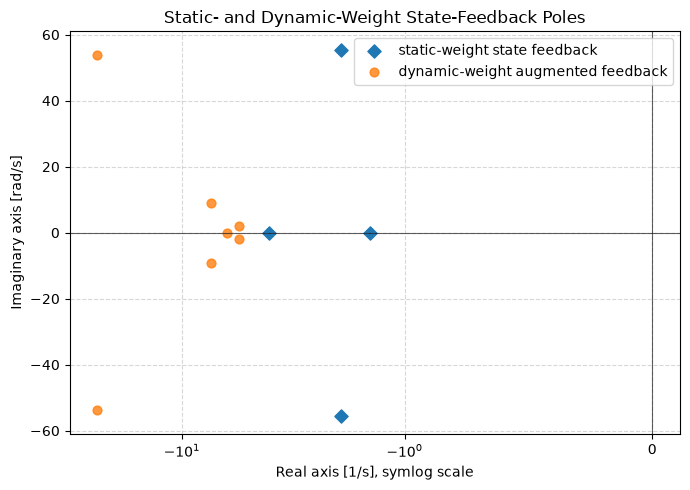

In [25]:
dynamic_hinf_state_dim = A_dyn_scaled.shape[0]

print(f"Dynamic-weight augmented dimension: {dynamic_hinf_state_dim}")

dynamic_hinf_config = SolverConfig()
dynamic_hinf_config.dual_feas_tol = 1e-4
dynamic_hinf_config.duality_gap_tol = 1e-4

dynamic_hinf_feedback_result = controls.solve_hinf_state_feedback(
    A_dyn_scaled,
    B_dyn_scaled,
    C_p_dyn_scaled,
    D_p_dyn_scaled,
    exogenous_dim=1, config=dynamic_hinf_config,
)

K_dyn_hinf_scaled = np.asarray(dynamic_hinf_feedback_result.K, dtype=np.float64)
K_dyn_hinf = input_scale_values[1] * K_dyn_hinf_scaled @ S_dyn_state_inv

A_dyn_scaled_cl = A_dyn_scaled + B_dyn_scaled[:, [1]] @ K_dyn_hinf_scaled
C_p_dyn_scaled_cl = C_p_dyn_scaled + D_p_dyn_scaled[:, [1]] @ K_dyn_hinf_scaled
dynamic_scaled_peak, dynamic_scaled_peak_frequency = estimate_hinf_norm(
    A_dyn_scaled_cl,
    B_dyn_scaled[:, [0]],
    C_p_dyn_scaled_cl,
    D_p_dyn_scaled[:, [0]],
    scaled_frequency_grid,
)
dynamic_scaled_bounded = dynamic_scaled_peak <= dynamic_hinf_feedback_result.gamma * (
    1.0 + 1e-4
)

A_dyn_hinf_cl = A_dyn_aug + B_dyn_aug[:, [1]] @ K_dyn_hinf
dynamic_hinf_cl_poles = np.linalg.eigvals(A_dyn_hinf_cl)


print(f"Solver status: {dynamic_hinf_feedback_result.status}")
print(f"Solver event: {dynamic_hinf_feedback_result.event}")
print(f"Iterations: {dynamic_hinf_feedback_result.num_iter}")
print(f"Dynamic-weight gamma: {dynamic_hinf_feedback_result.gamma:.6g}")
print(
    "Dynamic normalized ||r_bar -> z_p||_inf: "
    f"{dynamic_scaled_peak:.6g} at "
    f"{dynamic_scaled_peak_frequency:.3e} rad/tau"
)
print(f"Dynamic norm bounded by gamma? {dynamic_scaled_bounded}")
print(f"K_dyn_hinf physical augmented gain =\n{K_dyn_hinf}")
print(f"Dynamic-weight closed-loop poles: {dynamic_hinf_cl_poles}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.axvline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.scatter(
    np.real(hinf_closed_loop_poles),
    np.imag(hinf_closed_loop_poles),
    marker="D",
    s=45,
    label="static-weight state feedback",
)
ax.scatter(
    np.real(dynamic_hinf_cl_poles),
    np.imag(dynamic_hinf_cl_poles),
    marker="o",
    s=40,
    alpha=0.8,
    label="dynamic-weight augmented feedback",
)
ax.set_title("Static- and Dynamic-Weight State-Feedback Poles")
ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_xlabel("Real axis [1/s], symlog scale")
ax.set_ylabel("Imaginary axis [rad/s]")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

### Dynamically Weighted Measured-Output Compensator

Partition the augmented feedback gain as

$$
K_{aug}=\begin{bmatrix}K_z&K_W\end{bmatrix},
\qquad
u=K_z\hat z+K_Wx_W.
$$

The observer estimates the physical state $z$, while $x_W$ contains the dynamic-weight filter states. For the three filtered channels used here, $B_WD_{qr}=0$, so their update does not require the road input:

$$
\dot{\hat z}=A\hat z+B_uu+L(y-C_y\hat z),
$$

$$
\dot x_W=A_Wx_W+B_W(C_q\hat z+D_{qu}u).
$$

#### Compensator Realization

The standalone compensator maps the measured output $y$ to the actuator command $u$. Its internal state contains both the state estimate and the weighting-filter states:

$$
\xi=\begin{bmatrix}\hat z\\x_W\end{bmatrix}.
$$

After substituting $u=K_z\hat z+K_Wx_W$,

$$
\dot\xi=A_K\xi+B_Ky,
\qquad
u=C_K\xi,
$$

with

$$
A_K=
\begin{bmatrix}
A+B_uK_z-LC_y&B_uK_W\\
B_W(C_q+D_{qu}K_z)&A_W+B_WD_{qu}K_W
\end{bmatrix},
$$

$$
B_K=\begin{bmatrix}L\\0\end{bmatrix},
\qquad
C_K=\begin{bmatrix}K_z&K_W\end{bmatrix},
\qquad
D_K=0.
$$

Therefore, the compensator transfer matrix is

$$
K_{yu}(s)=C_K(sI-A_K)^{-1}B_K+D_K.
$$

The compensator input is only $y$; $\hat z$ and $x_W$ are internal states. Road disturbance $r$ enters the plant, while sensor noise $n$ enters through the measured output.

#### Part 5 Plant and Compensator Realization

Connect the compensator to

$$
\dot z=Az+B_uu+B_wr,
\qquad
y=C_yz+n.
$$

Substituting $y=C_yz+n$ into the compensator gives

$$
\dot\xi=A_K\xi+B_KC_yz+B_Kn.
$$

Thus, $B_KC_yz$ is part of the closed-loop dynamics, while $B_Kn$ is the external noise input. Since $B_K=[L^{\mathsf T},\,0]^{\mathsf T}$, noise enters the observer state directly and reaches the filter states and control input through the compensator dynamics.

Using $x_{cl}=[z^{\mathsf T},\,\xi^{\mathsf T}]^{\mathsf T}$ and $d=[r,\,n^{\mathsf T}]^{\mathsf T}$ then gives

$$
\dot x_{cl}=
\underbrace{\begin{bmatrix}
A&B_uC_K\\
B_KC_y&A_K
\end{bmatrix}}_{A_{cl}}x_{cl}
+
\underbrace{\begin{bmatrix}
B_w&0\\
0&B_K
\end{bmatrix}}_{B_{cl}}d.
$$

The physical performance output is

$$
q=
\underbrace{\begin{bmatrix}C_q&D_{qu}C_K\end{bmatrix}}_{C_{q,cl}}x_{cl}
+
\underbrace{\begin{bmatrix}D_{qr}&0\end{bmatrix}}_{D_{q,cl}}d.
$$

The augmented full state realization is used to synthesize $K_{aug}$. 

In [26]:
def dynamic_observer_based_closed_loop(K_aug, L):
    n = A.shape[0]
    K_z = K_aug[:, :n]
    K_W = K_aug[:, n:]
    filter_rows = slice(n, A_dyn_aug.shape[0])

    A_W = A_dyn_aug[filter_rows, filter_rows]
    B_WC_q = A_dyn_aug[filter_rows, :n]
    B_WD_qu = B_dyn_aug[filter_rows, [1]]

    A_K = np.block(
        [
            [A + B_u @ K_z - L @ C_y, B_u @ K_W],
            [B_WC_q + B_WD_qu @ K_z, A_W + B_WD_qu @ K_W],
        ]
    )
    B_K = np.vstack((L, np.zeros((K_W.shape[1], C_y.shape[0]))))
    C_K = np.hstack((K_z, K_W))
    D_K = np.zeros((B_u.shape[1], C_y.shape[0]))

    A_cl = np.block([[A, B_u @ C_K], [B_K @ C_y, A_K]])
    B_cl = np.block(
        [
            [B_w, np.zeros((n, C_y.shape[0]))],
            [np.zeros((A_K.shape[0], 1)), B_K],
        ]
    )
    C_q_cl = np.hstack((C_q, D_q[:, [1]] @ C_K))
    D_q_cl = np.hstack((D_q[:, [0]], np.zeros((C_q.shape[0], C_y.shape[0]))))
    return (A_K, B_K, C_K, D_K), (A_cl, B_cl, C_q_cl, D_q_cl)


dynamic_compensator, dynamic_closed_loop = dynamic_observer_based_closed_loop(
    K_dyn_hinf, L_hinf
)
A_K_dyn, B_K_dyn, C_K_dyn, D_K_dyn = dynamic_compensator
A_dyn_of, B_dyn_of, C_q_dyn_of, D_q_dyn_of = dynamic_closed_loop
dynamic_observer_poles = np.linalg.eigvals(A_dyn_of)

print(f"Dynamic plant + compensator poles: {dynamic_observer_poles}")
print(
    "Dynamic plant + compensator stable? "
    f"{np.all(np.real(dynamic_observer_poles) < 0.0)}"
)

Dynamic plant + compensator poles: [-2559.72166721 +0.j          -222.72455059 +0.j
   -24.021044  +53.82366004j   -24.021044  -53.82366004j
    -7.4460987  +9.11195002j    -7.4460987  -9.11195002j
    -2.86179585 +0.j            -5.55625728 +1.95480797j
    -5.55625728 -1.95480797j    -6.27419014 +0.j
    -9.09017826 +0.j        ]
Dynamic plant + compensator stable? True


### Dynamic Compensator Check

The augmented full-state norm above is the synthesis certificate. The standalone measured-output compensator is checked separately through its poles and peak $y\rightarrow u$ gain achieved over the frequency sweep.

Standalone dynamic compensator poles: [-2.55962727e+03+0.j         -2.22837234e+02+0.j
 -1.39608388e+00+0.j         -1.01132048e+01+7.88745207j
 -1.01132048e+01-7.88745207j -6.28293875e+00+0.j
 -1.15287365e+01+0.j        ]
Standalone dynamic compensator peak ||y -> u||: 21045.5 at 0.100 rad/s


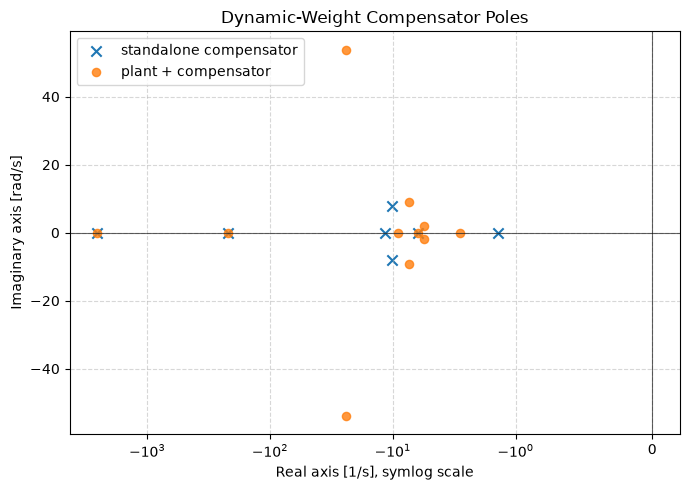

In [27]:
dynamic_compensator_poles = np.linalg.eigvals(A_K_dyn)
dynamic_compensator_peak, dynamic_compensator_peak_frequency = estimate_hinf_norm(
    A_K_dyn, B_K_dyn, C_K_dyn, D_K_dyn, frequency_grid
)

print(f"Standalone dynamic compensator poles: {dynamic_compensator_poles}")
print(
    "Standalone dynamic compensator peak ||y -> u||: "
    f"{dynamic_compensator_peak:.6g} at "
    f"{dynamic_compensator_peak_frequency:.3f} rad/s"
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.axvline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.scatter(
    np.real(dynamic_compensator_poles),
    np.imag(dynamic_compensator_poles),
    marker="x",
    s=55,
    label="standalone compensator",
)
ax.scatter(
    np.real(dynamic_observer_poles),
    np.imag(dynamic_observer_poles),
    marker="o",
    s=35,
    alpha=0.8,
    label="plant + compensator",
)
ax.set_title("Dynamic-Weight Compensator Poles")
ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_xlabel("Real axis [1/s], symlog scale")
ax.set_ylabel("Imaginary axis [rad/s]")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

<a id="part-6-mixed-sensitivity-comparison"></a>
## Part 6 — $S/T/KS$ Mixed-Sensitivity Synthesis

Parts 3 & 5 shape application specific $r \to z_p$ maps. Part 6 starts from the standard negative-feedback loop and shapes its sensitivity, complementary sensitivity, and control sensitivity maps. The weights are assembled into an explicit generalized plant and passed to the same canonical `hinf_state_feedback` interface used in Part 3 & 5.

The conventional mixed-sensitivity objective is

$$
\min_K\left\lVert \begin{bmatrix}W_S\,S\\W_T\,T\\W_{KS}\,KS\end{bmatrix}\right\rVert_\infty.
$$

where

- Lower frequency: $W_S\,S$ is desired to be small, enabling good closed-loop tracking and disturbance rejection.
- Mid/high frequency: $W_T\,T$ shapes roll-off to attenuate noise and avoid amplifying unmodeled dynamics.
- Control effort: $W_{KS}\,KS$ limits actuator demand, especially at higher frequencies. 

The internal signal map supplies the intuition for these three channels with $G$ denoting the generalized plant:

$$
\begin{align*}
e &= r_{ref}-y, \\
u &= Ke, \\
y &= Gu+d \\
  &= GK(r_{ref}-y)+d, \\
(I+GK)y &= GKr_{ref}+d.
\end{align*}
$$

The corresponding closed-loop maps are

$$
\begin{align*}
S  &= (I+GK)^{-1}, \\
T  &= GK(I+GK)^{-1}=G\,KS, \\
KS &= K(I+GK)^{-1}, \\
I  &= S+T.
\end{align*}
$$

This signal map makes the frequency-domain tradeoff explicit:

- When $r_{ref}=0$, $y=Sd$, so making $S$ small attenuates additive output disturbances.
- When $d=0$, $y=Tr_{ref}$ and $e=(I-T)r_{ref}=Sr_{ref}$, so making $S$ small enables tracking while $T$ approaches $I$.
- With $d=0$, $u=KS\,r_{ref}$, so the $W_{KS}\,KS$ channel exposes the actuator effort required to obtain that tracking response.
- Typically the design seeks $S\approx0$ and $T\approx I$ at low frequency, then allows $S$ to rise and forces $T$ to roll off at high frequency.

#### From the Part 5 Transfer Functions to the Mixed-Sensitivity Filters

As in Part 5, begin with physical signals and unit-bearing weighting transfer functions:

$$
q_{MIX}=\begin{bmatrix}q_S\\q_T\\q_{KS}\end{bmatrix}
=\begin{bmatrix}e\\y\\u\end{bmatrix},\qquad
z_p=\begin{bmatrix}W_S(s)e\\W_T(s)y\\W_{KS}(s)u\end{bmatrix}.
$$

Each diagonal weight uses the same first-order lead/lag form derived in Part 5:

$$
W_i(s)=\frac{G_{\infty,i}s+G_{0,i}\omega_{c,i}}{s+\omega_{c,i}},
\qquad i\in\{S,T,KS\},
$$

where $G_{0,i}$ and $G_{\infty,i}$ are diagonal shelf-gain matrices. Their diagonal entries weight the individual components of $q_S=e$, $q_T=y$, and $q_{KS}=u$, while all components within a given weight share the same cutoff $\omega_{c,i}$.

Applying the Part 5 realization channel-wise gives

$$
A_i=-\omega_{c,i}I,\qquad B_i=\omega_{c,i}I,\qquad
C_i=G_{0,i}-G_{\infty,i},\qquad D_i=G_{\infty,i},
$$

so that $\dot x_i=A_ix_i+B_iq_i$ and $z_i=C_ix_i+D_iq_i$. For this notebook, $x_S$ and $x_T$ each contain one filter state per component of $e$ and $y$; $x_{KS}$ contains one state because there is one actuator input. These physical filter realizations are interconnected with the physical plant below.

To make the physical comparison more representative, the body-velocity shelf of $W_T$ and the full $W_{KS}$ shelf are each reduced by a factor of 10. This preserves their frequency shapes and shelf ratios while giving $W_S$ more relative influence over body-mode rejection. The selected scaling keeps the resulting actuator force comparable to the static and dynamic designs.

### Explicit Mixed-Sensitivity Augmentation

First write the quarter-car plant and generalized inputs entirely in physical coordinates:

$$
\dot z=Az+B_u u,\qquad y=C_yz+D_{yu}u,\qquad
v_{MIX}=\begin{bmatrix}r_{ref}^{\mathsf T}&u^{\mathsf T}\end{bmatrix}^{\mathsf T}.
$$

For this quarter-car measurement $D_{yu}=0$. Substituting $q_S=e=r_{ref}-y$, $q_T=y$, and $q_{KS}=u$ into the reused Part 5 filter realization gives the three physical-input, physical-time subsystems below.

**Sensitivity weight $W_S$**
$$
\dot{x}_S = A_S x_S + B_S q_S \\
z_S = C_S x_S + D_S q_S
$$

**Complementary-sensitivity weight $W_T$**
$$
\dot{x}_T = A_T x_T + B_T q_T \\
z_T = C_T x_T + D_T q_T
$$

**Control-sensitivity weight $W_{KS}$**
$$
\dot{x}_{KS} = A_{KS} x_{KS} + B_{KS} q_{KS} \\
z_{KS} = C_{KS} x_{KS} + D_{KS} q_{KS}.
$$

Stack the physical plant and physical-signal filter states:

$$
z_{MIX}=\begin{bmatrix}z^{\mathsf T}&x_S^{\mathsf T}&x_T^{\mathsf T}&x_{KS}^{\mathsf T}\end{bmatrix}^{\mathsf T}.
$$

Interconnecting these physical-input weight matrices with the plant produces the mixed-sensitivity augmented plant. 

$$
A_{MIX}=
\begin{bmatrix}
A&0&0&0\\
-B_SC_y&A_S&0&0\\
B_TC_y&0&A_T&0\\
0&0&0&A_{KS}
\end{bmatrix},\qquad
B_{MIX}=
\begin{bmatrix}
0&B_u\\
B_S&-B_SD_{yu}\\
0&B_TD_{yu}\\
0&B_{KS}
\end{bmatrix},
$$

$$
C_{p,MIX}=
\begin{bmatrix}
-D_SC_y&C_S&0&0\\
D_TC_y&0&C_T&0\\
0&0&0&C_{KS}
\end{bmatrix},\qquad
D_{p,MIX}=
\begin{bmatrix}
D_S&-D_SD_{yu}\\
0&D_TD_{yu}\\
0&D_{KS}
\end{bmatrix}.
$$

These matrices realize $\dot z_{MIX}=A_{MIX}z_{MIX}+B_{MIX}v_{MIX}$ and $z_p=C_{p,MIX}z_{MIX}+D_{p,MIX}v_{MIX}$ before any solver-coordinate transformation. 

#### Mixed-Sensitivity Signals and Systems Diagram

```mermaid
flowchart LR
    r["Reference r"] -->|"+"| sumE(("Σ"))
    sumE -->|"error e"| e_sig(( ))
    e_sig --> K["Controller K"]
    K -->|"control u"| G["Plant G"]
    G -->|"plant output y"| sumY(("Σ"))
    d["Output disturbance d"] -->|"+"| sumY

    sumY -->|"output y"| sumN(("Σ"))
    n["Sensor noise n"] -->|"+"| sumN
    sumN -->|"- measured signal y + n"| sumE

    e_sig --> WS["W_S"]
    sumY --> WT["W_T"]
    K --> WKS["W_KS"]

    WS --> zS["z_S"]
    WT --> zT["z_T"]
    WKS --> zKS["z_KS"]

    classDef block fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;
    classDef signal fill:#ffffff,stroke:#111111,stroke-width:1.3px,color:#111111;
    classDef junction fill:#ffffff,stroke:#111111,stroke-width:1.5px,color:#111111;

    class G,K,WS,WT,WKS block;
    class r,d,n,zS,zT,zKS signal;
    class sumE,sumY,sumN,e_sig junction;
```

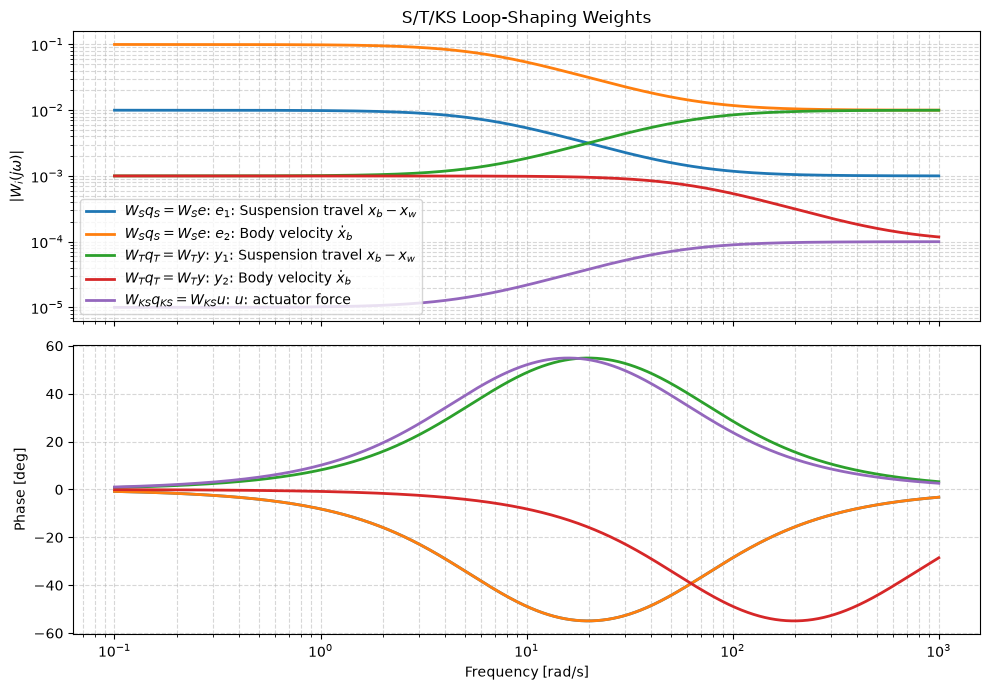

Physical-input S/T/KS shelf poles:
[ -6.28318531  -6.28318531 -62.83185307 -62.83185307 -50.26548246]


In [28]:
T_MIX_REF = 1e-2  # tau_MIX = t / T_MIX_REF


def diagonal_lead_lag_realization(G_0, G_inf, omega_c):
    G_0 = np.asarray(G_0, dtype=np.float64)
    G_inf = np.asarray(G_inf, dtype=np.float64)
    if G_0.shape != G_inf.shape or G_0.ndim != 1:
        raise ValueError("G_0 and G_inf must be same-length gain vectors")
    dimension = G_0.size
    A_weight = -omega_c * np.eye(dimension, dtype=np.float64)
    B_weight = omega_c * np.eye(dimension, dtype=np.float64)
    C_weight = np.diag(G_0 - G_inf)
    D_weight = np.diag(G_inf)
    return A_weight, B_weight, C_weight, D_weight


MIX_WEIGHT_CHANNELS = {
    r"$W_S q_S = W_S e$": {
        "G_0": np.array([1e-2, 1e-1]),
        "G_inf": np.array([1e-3, 1e-2]),
        "omega_c": 2.0 * np.pi,
    },
    r"$W_T q_T = W_T y$": {
        "G_0": np.array([1e-3, 1e-3]),
        "G_inf": np.array([1e-2, 1e-4]),
        "omega_c": 2.0 * np.pi * 10.0,
    },
    r"$W_{KS} q_{KS} = W_{KS} u$": {
        "G_0": np.array([1e-5]),
        "G_inf": np.array([1e-4]),
        "omega_c": 2.0 * np.pi * 8.0,
    },
}
MIX_WEIGHT_CHANNEL_LABELS = {
    r"$W_S q_S = W_S e$": [
        rf"$e_1$: {MEASUREMENT_LABELS[0]}",
        rf"$e_2$: {MEASUREMENT_LABELS[1]}",
    ],
    r"$W_T q_T = W_T y$": [
        rf"$y_1$: {MEASUREMENT_LABELS[0]}",
        rf"$y_2$: {MEASUREMENT_LABELS[1]}",
    ],
    r"$W_{KS} q_{KS} = W_{KS} u$": [r"$u$: actuator force"],
}

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for label, weight in MIX_WEIGHT_CHANNELS.items():
    for channel_label, G_0, G_inf in zip(
        MIX_WEIGHT_CHANNEL_LABELS[label],
        weight["G_0"],
        weight["G_inf"],
        strict=True,
    ):
        response = lead_lag_response(G_0, G_inf, weight["omega_c"], frequency_grid)
        plot_label = f"{label}: {channel_label}"
        axes[0].loglog(
            frequency_grid, np.abs(response), linewidth=2.0, label=plot_label
        )
        axes[1].semilogx(
            frequency_grid,
            np.degrees(np.unwrap(np.angle(response))),
            linewidth=2.0,
            label=plot_label,
        )

axes[0].set_title("S/T/KS Loop-Shaping Weights")
axes[0].set_ylabel(r"$|W_i(j\omega)|$")
axes[1].set_ylabel("Phase [deg]")
axes[1].set_xlabel("Frequency [rad/s]")
for ax in axes:
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
axes[0].legend(loc="best")
plt.tight_layout()
plt.show()

W_s_spec = MIX_WEIGHT_CHANNELS[r"$W_S q_S = W_S e$"]
W_t_spec = MIX_WEIGHT_CHANNELS[r"$W_T q_T = W_T y$"]
W_ks_spec = MIX_WEIGHT_CHANNELS[r"$W_{KS} q_{KS} = W_{KS} u$"]
W_s = diagonal_lead_lag_realization(**W_s_spec)
W_t = diagonal_lead_lag_realization(**W_t_spec)
W_ks = diagonal_lead_lag_realization(**W_ks_spec)

print("Physical-input S/T/KS shelf poles:")
print(np.concatenate([np.diag(W_s[0]), np.diag(W_t[0]), np.diag(W_ks[0])]))

### Non-dimensionalization and Scaling

The matrices above are in physical units and their inputs are physical signals $[r_{ref}^{\mathsf T},u^{\mathsf T}]^{\mathsf T}$. 

$$
z_{MIX}=S_{MIX}\bar z_{MIX},\qquad
S_{MIX}=\operatorname{diag}(S_z,S_y,S_y,S_u),\qquad
v_{MIX}=S_{in,MIX}\bar v_{MIX},\qquad
S_{in,MIX}=\operatorname{diag}(S_y,S_u),\qquad
\tau_{MIX}=t/T_{MIX,ref}.
$$

The normalized generalized plant is therefore

$$
\bar A_{MIX}=T_{MIX,ref}S_{MIX}^{-1}A_{MIX}S_{MIX},\qquad
\bar B_{MIX}=T_{MIX,ref}S_{MIX}^{-1}B_{MIX}S_{in,MIX},
$$

$$
\bar C_{p,MIX}=C_{p,MIX}S_{MIX},\qquad
\bar D_{p,MIX}=D_{p,MIX}S_{in,MIX}.
$$

After this step, both $\bar z_{MIX}$ and $\bar v_{MIX}=[\bar r_{ref}^{\mathsf T},\bar u^{\mathsf T}]^{\mathsf T}$ are dimensionless, and the input columns follow the solver's required $[w,u]$ order. The solver returns $\bar u=\bar K_{MIX}\bar z_{MIX}$, and the achieved $\bar r_{ref} \to z_p$ norm is checked on this same scaled realization.

In [29]:
def build_mix_augmented_plant(A, B_u, C_y, D_yu, W_s, W_t, W_ks):
    """Build the physical plant with physical [r_ref, u] inputs."""
    A_s, B_s, C_s, D_s = W_s
    A_t, B_t, C_t, D_t = W_t
    A_ks, B_ks, C_ks, D_ks = W_ks

    n = A.shape[0]
    ns, nt, n_ks = A_s.shape[0], A_t.shape[0], A_ks.shape[0]
    p, m = C_y.shape[0], B_u.shape[1]
    x = slice(0, n)
    x_s = slice(n, n + ns)
    x_t = slice(n + ns, n + ns + nt)
    x_ks = slice(n + ns + nt, n + ns + nt + n_ks)

    A_mix = np.zeros((x_ks.stop, x_ks.stop))
    B_mix = np.zeros((x_ks.stop, p + m))
    C_p_mix = np.zeros((C_s.shape[0] + C_t.shape[0] + C_ks.shape[0], x_ks.stop))
    D_p_mix = np.zeros((C_p_mix.shape[0], p + m))

    A_mix[x, x] = A
    A_mix[x_s, x] = -B_s @ C_y
    A_mix[x_s, x_s] = A_s
    A_mix[x_t, x] = B_t @ C_y
    A_mix[x_t, x_t] = A_t
    A_mix[x_ks, x_ks] = A_ks

    B_mix[x, p:] = B_u
    B_mix[x_s, :p] = B_s
    B_mix[x_s, p:] = -B_s @ D_yu
    B_mix[x_t, p:] = B_t @ D_yu
    B_mix[x_ks, p:] = B_ks

    z_s = slice(0, C_s.shape[0])
    z_t = slice(z_s.stop, z_s.stop + C_t.shape[0])
    z_ks = slice(z_t.stop, z_t.stop + C_ks.shape[0])
    C_p_mix[z_s, x] = -D_s @ C_y
    C_p_mix[z_s, x_s] = C_s
    C_p_mix[z_t, x] = D_t @ C_y
    C_p_mix[z_t, x_t] = C_t
    C_p_mix[z_ks, x_ks] = C_ks
    D_p_mix[z_s, :p] = D_s
    D_p_mix[z_s, p:] = -D_s @ D_yu
    D_p_mix[z_t, p:] = D_t @ D_yu
    D_p_mix[z_ks, p:] = D_ks
    return A_mix, B_mix, C_p_mix, D_p_mix


D_yu_physical = np.zeros((C_y.shape[0], B_u.shape[1]))
(
    A_mix_physical,
    B_mix_physical,
    C_p_mix_physical,
    D_p_mix_physical,
) = build_mix_augmented_plant(
    A,
    B_u,
    C_y,
    D_yu_physical,
    W_s,
    W_t,
    W_ks,
)

n = A.shape[0]
s_dim = W_s[0].shape[0]
t_dim = W_t[0].shape[0]
ks_dim = W_ks[0].shape[0]
p_mix = C_y.shape[0]
S_u = np.diag([input_scale_values[1]])
S_mix_state = np.diag(
    np.concatenate(
        (state_scale_values, meas_scale_values, meas_scale_values, np.diag(S_u))
    )
)
S_mix_state_inv = np.diag(1.0 / np.diag(S_mix_state))
S_mix_input = np.diag(np.concatenate((meas_scale_values, np.diag(S_u))))

A_mix_scaled = T_MIX_REF * (S_mix_state_inv @ A_mix_physical @ S_mix_state)
B_mix_scaled = T_MIX_REF * (S_mix_state_inv @ B_mix_physical @ S_mix_input)
C_p_mix_scaled = C_p_mix_physical @ S_mix_state
D_p_mix_scaled = D_p_mix_physical @ S_mix_input

In [30]:
mix_config = SolverConfig()
mix_config.dual_feas_tol = 5e-5
mix_feedback_result = controls.solve_hinf_state_feedback(
    A_mix_scaled,
    B_mix_scaled,
    C_p_mix_scaled,
    D_p_mix_scaled,
    exogenous_dim=2, config=mix_config,
)

K_mix_scaled = np.asarray(mix_feedback_result.K, dtype=np.float64)
K_mix_physical = S_u @ K_mix_scaled @ S_mix_state_inv
K_mix_x = K_mix_physical[:, :n]
K_mix_s = K_mix_physical[:, n : n + s_dim]
K_mix_t = K_mix_physical[:, n + s_dim : n + s_dim + t_dim]
K_mix_ks = K_mix_physical[:, n + s_dim + t_dim :]

A_mix_scaled_cl = A_mix_scaled + B_mix_scaled[:, p_mix:] @ K_mix_scaled
C_p_mix_scaled_cl = C_p_mix_scaled + D_p_mix_scaled[:, p_mix:] @ K_mix_scaled
mix_scaled_frequency_grid = np.logspace(-7, 2, 6_000)
mix_scaled_peak, mix_scaled_peak_frequency = estimate_hinf_norm(
    A_mix_scaled_cl,
    B_mix_scaled[:, :p_mix],
    C_p_mix_scaled_cl,
    D_p_mix_scaled[:, :p_mix],
    mix_scaled_frequency_grid,
)
mix_scaled_bounded = mix_scaled_peak <= mix_feedback_result.gamma * (1.0 + 1e-3)
mix_state_feedback_poles = np.linalg.eigvals(A_mix_scaled_cl)

print("Mixed-sensitivity solver diagnostics")
print(f"  status: {mix_feedback_result.status}")
print(f"  event: {mix_feedback_result.event}")
print(f"  stalled: {mix_feedback_result.stalled}")
print(f"  iterations: {mix_feedback_result.num_iter}")
print(f"  gamma: {mix_feedback_result.gamma:.6g}")
print(
    f"  normalized duality gap (mu): {mix_feedback_result.normalized_duality_gap:.3e}"
)
print(f"  primal objective: {mix_feedback_result.primal_objective_value:.6e}")
print(f"  dual objective: {mix_feedback_result.dual_objective_value:.6e}")
print("  residual norms:")
print(f"    primal: {mix_feedback_result.primal_residual_norm:.3e}")
print(f"    dual: {mix_feedback_result.dual_residual_norm:.3e}")
print(f"    equality: {mix_feedback_result.equality_residual_norm:.3e}")
print("  configured tolerances:")
print(f"    primal feasibility: {mix_config.primal_feas_tol:.1e}")
print(f"    dual feasibility: {mix_config.dual_feas_tol:.1e}")
print(f"    duality gap: {mix_config.duality_gap_tol:.1e}")
print(f"K_mix physical-state gain =\n{K_mix_x}")
print(
    "S/T/KS normalized achieved norm: "
    f"{mix_scaled_peak:.6g} at {mix_scaled_peak_frequency:.3e} rad/tau"
)
print(f"S/T/KS norm bounded by gamma? {mix_scaled_bounded}")
print(f"S/T/KS augmented state-feedback poles: {mix_state_feedback_poles}")

Mixed-sensitivity solver diagnostics
  status: OPTIMAL
  event: NONE
  stalled: False
  iterations: 14
  gamma: 0.0500108
  normalized duality gap (mu): 9.040e-06
  primal objective: 5.001077e-02
  dual objective: 4.987123e-02
  residual norms:
    primal: 1.000e-10
    dual: 1.000e-10
    equality: 0.000e+00
  configured tolerances:
    primal feasibility: 1.0e-05
    dual feasibility: 5.0e-05
    duality gap: 1.0e-05
K_mix physical-state gain =
[[-6.03704293e+02 -5.62695911e+02  2.90307332e+03  2.85119112e+00]]
S/T/KS normalized achieved norm: 0.0500001 at 1.000e-07 rad/tau
S/T/KS norm bounded by gamma? True
S/T/KS augmented state-feedback poles: [-0.24161922+0.5376252j  -0.24161922-0.5376252j  -0.62831853+0.j
 -0.6284106 +0.j         -0.0441427 +0.09769108j -0.0441427 -0.09769108j
 -0.08390551+0.j         -0.06259154+0.j         -0.06283185+0.j        ]


### $S/T/KS$ Measured-Output Compensator

Like before, the synthesized controller gain will act on $z$ as well as the augmented filter states. To now pose this problem in terms of an output feedback dynamic compensator, the controller will now operate on the estimate of $\hat{z}$

$$
\xi=\begin{bmatrix}\hat z^{\mathsf T}&x_S^{\mathsf T}&x_T^{\mathsf T}&x_{KS}^{\mathsf T}\end{bmatrix}^{\mathsf T}.
$$

#### Standalone Dynamic Compensator

The implementation realizes the dynamic map from measured output $y$ to actuator force $u$ as

$$
\dot\xi=A_K\xi+B_Ky,\qquad
u=C_K\xi+D_Ky,\qquad D_K=0.
$$

$\hat z$ contains the observer dynamics, while $x_S$, $x_T$, and $x_{KS}$ retain the frequency-dependent memory required by the mixed-sensitivity gain. Note that this setup is the regulator specialization $r_{\mathrm{ref}}=0$.

#### Physical Plant + Compensator

The closed-loop analysis uses the same interconnection derived in the [Part 5 plant-and-compensator realization](#part-5-plant-and-compensator-realization), with the mixed-sensitivity matrices $(A_K,B_K,C_K,D_K)$ substituted for the Part 5 compensator. Thus $x_{cl}=[z^{\mathsf T},\xi^{\mathsf T}]^{\mathsf T}$ and the external inputs remain the physical road and sensor noise, $d=[r,n^{\mathsf T}]^{\mathsf T}$.

Relative to the [mixed-sensitivity signals-and-systems diagram](#mixed-sensitivity-signals-and-systems-diagram), this post synthesis analysis reconnects the physical quarter car plant: road disturbance enters through $B_wr$, sensor noise enters the compensator through $y+n$.

In [31]:
def mix_observer_based_closed_loop(K_x, K_s, K_t, K_ks, L):
    A_s, B_s, _, _ = W_s
    A_t, B_t, _, _ = W_t
    A_ks, B_ks, _, _ = W_ks

    n = A.shape[0]
    s_dim = A_s.shape[0]
    t_dim = A_t.shape[0]
    ks_dim = A_ks.shape[0]
    compensator_dim = n + s_dim + t_dim + ks_dim
    zhat = slice(0, n)
    x_s = slice(n, n + s_dim)
    x_t = slice(n + s_dim, n + s_dim + t_dim)
    x_ks = slice(n + s_dim + t_dim, compensator_dim)

    A_K = np.zeros((compensator_dim, compensator_dim), dtype=np.float64)
    A_K[zhat, zhat] = A - L @ C_y + B_u @ K_x
    A_K[zhat, x_s] = B_u @ K_s
    A_K[zhat, x_t] = B_u @ K_t
    A_K[zhat, x_ks] = B_u @ K_ks
    A_K[x_s, zhat] = -B_s @ C_y
    A_K[x_s, x_s] = A_s
    A_K[x_t, zhat] = B_t @ C_y
    A_K[x_t, x_t] = A_t

    A_K[x_ks, zhat] = B_ks @ K_x
    A_K[x_ks, x_s] = B_ks @ K_s
    A_K[x_ks, x_t] = B_ks @ K_t
    A_K[x_ks, x_ks] = A_ks + B_ks @ K_ks

    # Regulator realization: r_ref = 0, so B_K contains only y-input columns.
    # Tracking would add B_K_r = vstack((0, B_s, 0, 0)); D_K_r remains zero.
    B_K = np.vstack((L, np.zeros((compensator_dim - n, C_y.shape[0]))))
    C_K = np.hstack((K_x, K_s, K_t, K_ks))
    D_K = np.zeros((B_u.shape[1], C_y.shape[0]))

    A_cl = np.block([[A, B_u @ C_K], [B_K @ C_y, A_K]])
    B_cl = np.block(
        [
            [B_w, np.zeros((n, C_y.shape[0]))],
            [np.zeros((compensator_dim, 1)), B_K],
        ]
    )
    C_q_cl = np.hstack((C_q, D_q[:, [1]] @ C_K))
    D_q_cl = np.hstack((D_q[:, [0]], np.zeros((C_q.shape[0], C_y.shape[0]))))
    return (A_K, B_K, C_K, D_K), (A_cl, B_cl, C_q_cl, D_q_cl)


mix_compensator, mix_closed_loop = mix_observer_based_closed_loop(
    K_mix_x, K_mix_s, K_mix_t, K_mix_ks, L_hinf
)
A_K_mix, B_K_mix, C_K_mix, D_K_mix = mix_compensator
A_mix_of, B_mix_of, C_q_mix_of, D_q_mix_of = mix_closed_loop
mix_observer_poles = np.linalg.eigvals(A_mix_of)
print(f"S/T/KS plant + compensator poles: {mix_observer_poles}")
print(f"S/T/KS plant + compensator stable? {np.all(np.real(mix_observer_poles) < 0.0)}")

S/T/KS plant + compensator poles: [-2559.72166721 +0.j          -222.72455059 +0.j
   -24.16192209+53.76251988j   -24.16192209-53.76251988j
   -62.84106003 +0.j           -62.83185307 +0.j
    -4.41427036 +9.76910752j    -4.41427036 -9.76910752j
    -2.86179585 +0.j            -9.09017826 +0.j
    -8.39055112 +0.j            -6.25915366 +0.j
    -6.28318531 +0.j        ]
S/T/KS plant + compensator stable? True


### $S/T/KS$ Compensator Check

As in Part 5, report the standalone $y\rightarrow u$ peak separately from the augmented full-state certificate, then check the poles of both the compensator and the complete interconnection.

Standalone S/T/KS compensator poles: [-2.55981407e+03+0.j         -2.22738603e+02+0.j
 -6.28356294e+01+0.j         -6.28318531e+01+0.j
 -1.10465772e+01+6.88951013j -1.10465772e+01-6.88951013j
 -2.43085081e+00+0.j         -6.30852142e+00+0.j
 -6.28318531e+00+0.j        ]
Standalone S/T/KS compensator peak ||y -> u||: 9339.4 at 0.100 rad/s


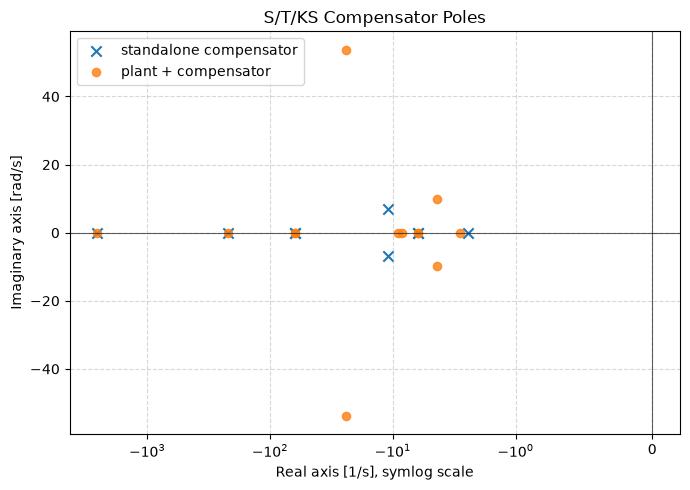

In [32]:
mix_compensator_poles = np.linalg.eigvals(A_K_mix)
mix_compensator_peak, mix_compensator_peak_frequency = estimate_hinf_norm(
    A_K_mix, B_K_mix, C_K_mix, D_K_mix, frequency_grid
)
print(f"Standalone S/T/KS compensator poles: {mix_compensator_poles}")
print(
    "Standalone S/T/KS compensator peak ||y -> u||: "
    f"{mix_compensator_peak:.6g} at "
    f"{mix_compensator_peak_frequency:.3f} rad/s"
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.axvline(0.0, color="k", linewidth=0.8, alpha=0.6)
ax.scatter(
    np.real(mix_compensator_poles),
    np.imag(mix_compensator_poles),
    marker="x",
    s=55,
    label="standalone compensator",
)
ax.scatter(
    np.real(mix_observer_poles),
    np.imag(mix_observer_poles),
    marker="o",
    s=35,
    alpha=0.8,
    label="plant + compensator",
)
ax.set_title("S/T/KS Compensator Poles")
ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_xlabel("Real axis [1/s], symlog scale")
ax.set_ylabel("Imaginary axis [rad/s]")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

### Four-Way Physical Step Comparison

Compare the passive, static-weight $H_\infty$, dynamic-weight $H_\infty$, and mixed-sensitivity realizations on the same physical quarter-car plant. The input is a persistent $r_0=0.025\,\mathrm{m}=25\,\mathrm{mm}$ road step.

For each realization,

$$
\dot x_{cl}=A_{cl}x_{cl}+B_{cl}r_0,
\qquad
q=C_{q,cl}x_{cl}+D_{q,cl}r_0.
$$

The steady-state values follow from (used in DC analysis)

$$
x_{ss}=-A_{cl}^{-1}B_{cl}r_0,
\qquad
q_{ss}=\left(D_{q,cl}-C_{q,cl}A_{cl}^{-1}B_{cl}\right)r_0.
$$

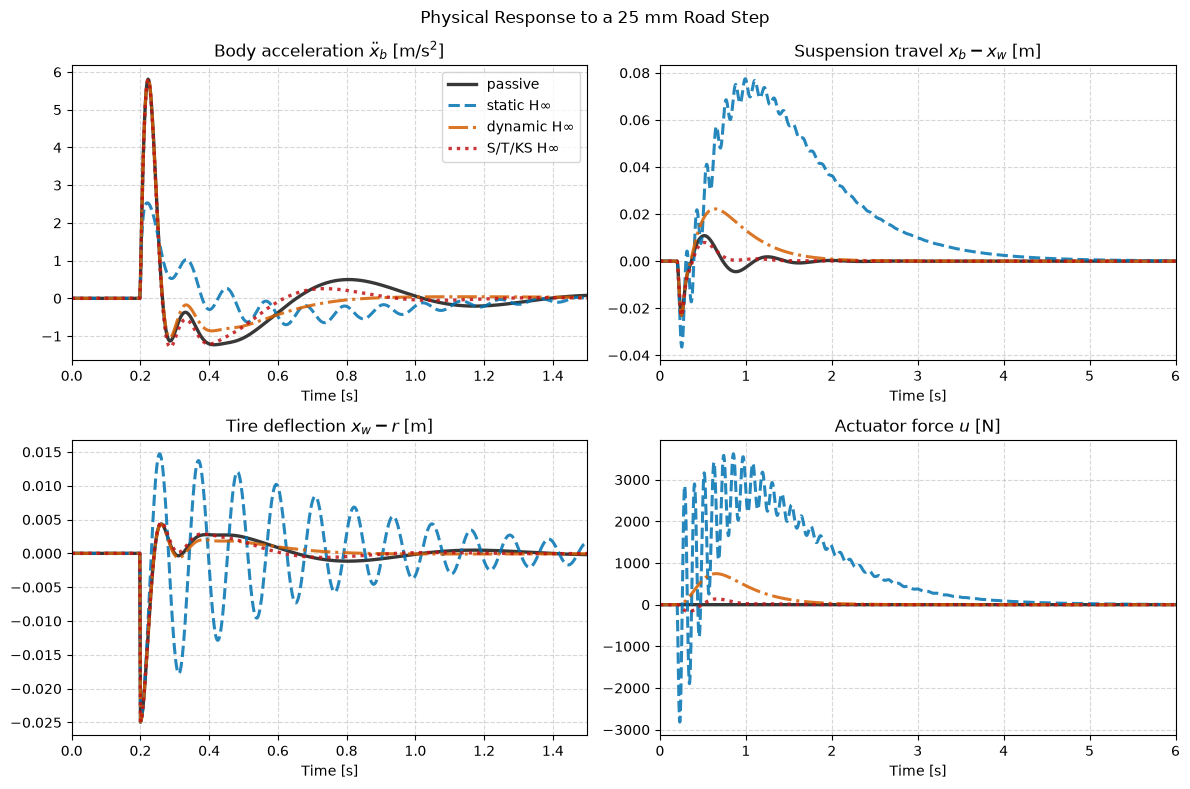

DC physical performance for the 25 mm road step:
  passive: [-8.88178420e-16  1.38777878e-17  3.46944695e-18  0.00000000e+00]
  static H∞: [-1.03002624e-15  3.73659437e-15  3.46944695e-18  1.48731586e-10]
  dynamic H∞: [-1.10691843e-15  2.70616862e-16  3.46944695e-18  1.02077640e-11]
  S/T/KS H∞: [-9.52025118e-16  2.77555756e-17  3.46944695e-18  4.85298959e-13]


In [33]:
t_response = np.linspace(0.0, 6.0, 3_000)
road_step = 0.025 * (t_response >= 0.2)
road_step_height = road_step[-1]

all_physical_systems = {
    "passive": (A, B_w, C_q, D_q[:, [0]]),
    "static H∞": (A_of, B_of[:, [0]], C_q_of, D_q_of[:, [0]]),
    "dynamic H∞": (A_dyn_of, B_dyn_of[:, [0]], C_q_dyn_of, D_q_dyn_of[:, [0]]),
    "S/T/KS H∞": (A_mix_of, B_mix_of[:, [0]], C_q_mix_of, D_q_mix_of[:, [0]]),
}

physical_plot_styles = {
    "passive": {"color": "#222222", "linestyle": "-", "linewidth": 2.4, "alpha": 0.9},
    "static H∞": {
        "color": "#0072B2",
        "linestyle": "--",
        "linewidth": 2.2,
        "alpha": 0.85,
    },
    "dynamic H∞": {
        "color": "#D55E00",
        "linestyle": "-.",
        "linewidth": 2.2,
        "alpha": 0.85,
    },
    "S/T/KS H∞": {
        "color": "#C11215",
        "linestyle": (0, (1, 1.5)),
        "linewidth": 2.4,
        "alpha": 0.85,
    },
}

step_responses = {}
dc_performance = {}
for name, (A_cl, B_cl, C_cl, D_cl) in all_physical_systems.items():
    _, response, _ = lsim(StateSpace(A_cl, B_cl, C_cl, D_cl), U=road_step, T=t_response)
    step_responses[name] = response
    x_ss = np.linalg.solve(A_cl, -(B_cl * road_step_height).ravel())
    dc_performance[name] = C_cl @ x_ss + D_cl[:, 0] * road_step_height

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for channel_index, (ax, label) in enumerate(
    zip(axes.flat, performance_labels, strict=True)
):
    for name, response in step_responses.items():
        ax.plot(
            t_response,
            response[:, channel_index],
            label=name,
            **physical_plot_styles[name],
        )
    ax.set_title(label)
    ax.set_xlabel("Time [s]")
    ax.grid(True, linestyle="--", alpha=0.5)

axes[0, 0].set_xlim(0.0, 1.5)
axes[1, 0].set_xlim(0.0, 1.5)
axes[0, 1].set_xlim(0.0, t_response[-1])
axes[1, 1].set_xlim(0.0, t_response[-1])
axes[0, 0].legend(loc="best")
fig.suptitle("Physical Response to a 25 mm Road Step")
plt.tight_layout()
plt.show()

print("DC physical performance for the 25 mm road step:")
for name, values in dc_performance.items():
    print(f"  {name}: {values}")

### Four-Way Physical Bode Comparison

Compare the physical road to channel maps $T_{r\rightarrow q_i}$ for all four realizations. These plots interpret the design tradeoffs in physical units; they are separate from the normalized synthesis certificates above.

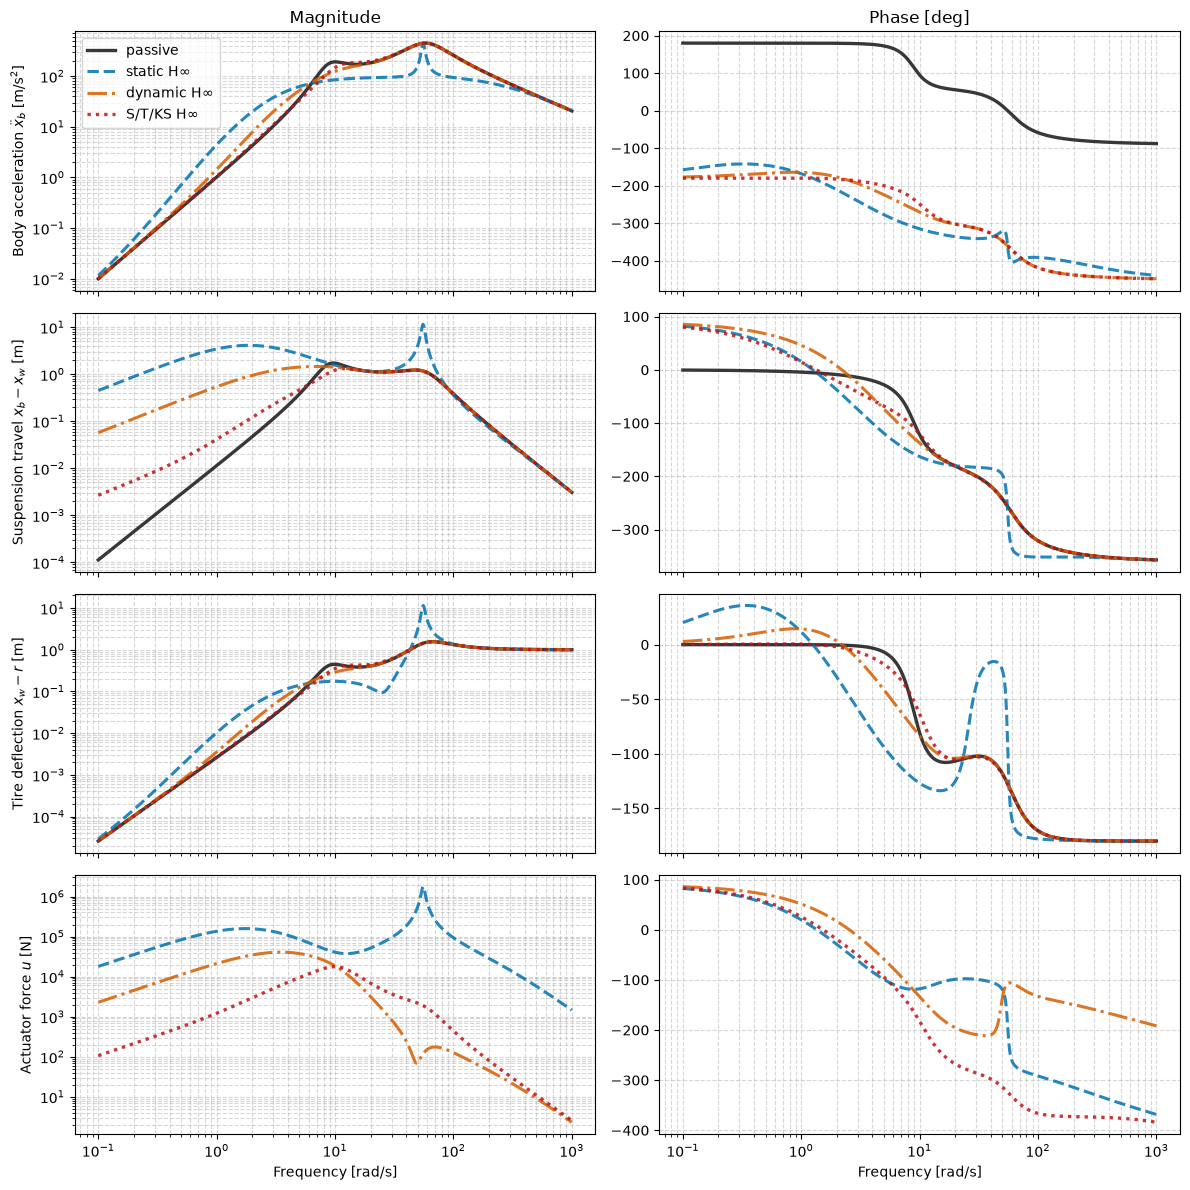

In [34]:
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)
for name, (A_cl, B_cl, C_cl, D_cl) in all_physical_systems.items():
    for channel_index in range(C_cl.shape[0]):
        response = channel_frequency_response(
            A_cl,
            B_cl,
            C_cl[[channel_index], :],
            D_cl[[channel_index], :],
            frequency_grid,
        )
        magnitude = np.abs(response)
        magnitude[magnitude < 1e-14] = np.nan
        axes[channel_index, 0].loglog(
            frequency_grid,
            magnitude,
            label=name,
            **physical_plot_styles[name],
        )
        phase = np.degrees(np.unwrap(np.angle(response)))
        phase[np.abs(response) < 1e-14] = np.nan
        axes[channel_index, 1].semilogx(
            frequency_grid,
            phase,
            label=name,
            **physical_plot_styles[name],
        )

for channel_index, label in enumerate(performance_labels):
    axes[channel_index, 0].set_ylabel(label)
    axes[channel_index, 0].grid(True, which="both", linestyle="--", alpha=0.5)
    axes[channel_index, 1].grid(True, which="both", linestyle="--", alpha=0.5)

axes[0, 0].set_title("Magnitude")
axes[0, 1].set_title("Phase [deg]")
axes[-1, 0].set_xlabel("Frequency [rad/s]")
axes[-1, 1].set_xlabel("Frequency [rad/s]")
axes[0, 0].legend(loc="best")
plt.tight_layout()
plt.show()

#### Physical Performance Tradeoffs

No controller dominates all four channels:

- **Ride comfort:** Static $H_\infty$ has the largest step peak ($\approx6.6\,\mathrm{m/s^2}$); dynamic $H_\infty$ improves the mid-band response with a smaller transient penalty. $S/T/KS$ gives the strongest rejection near $8$-$12\,\mathrm{rad/s}$, but a deeper first undershoot.

- **Suspension travel:** All active designs use more low-frequency stroke than passive. $S/T/KS$ uses less than the static/dynamic designs through most of that band, but holds $x_b-x_w<0$ inducing longer & greater suspension compression which results in unloading the tire deflection after the step input.

- **Road holding:** All controllers initially compress the tire, $x_w-z_r<0$. $S/T/KS$ then has the largest positive rebound, $x_w-z_r>0$: greater tire unloading and wheel hop (does not mean additional compression or loss of road contact).

- **Actuator effort:** Static, dynamic, and $S/T/KS$ peak near $0.85$, $1.15$, and $0.9\,\mathrm{kN}$. Mixed sensitivity therefore uses comparable authority, and the dynamic controller exhibits stronger high-frequency roll-off than static feedback.

```mermaid
flowchart TD
    r["Road disturbance: r"] --> P["Quarter-car plant"]
    P --> Q["Static / dynamic H∞<br/>Optimize road disturbance<br/>to weighted performance"]
    P --> M["Mixed S / T / KS<br/>Feedback: y = Cy z"]
    Q --> QT["Balance body, stroke,<br/>road holding, and force"]
    M --> MT["Isolate body mode;<br/>allow more wheel motion"]
```

In short, $S/T/KS$ isolates $r$ from $\ddot{x}_b$ near the $10\,\mathrm{rad/s}$ body resonance. Its negative transient force pulls the body down and wheel up, trading body isolation for longer suspension compression and a larger tire-unloading rebound. The static/dynamic objectives explicitly optimize $r\rightarrow W_qq$, while mixed sensitivity shapes the measured loop without an $r$ measurement or preview channel. Adding a road estimator or preview is possible, but outside this notebook series.

## Shadow Price Summary

Each solve has two PSD blocks: `c0` enforces $Q\succeq0$ and `c1` is the bounded-real performance LMI. The plotted value $p_i=\log_{10}(1+\lVert y_i\rVert_2)$ measures dual pressure; comparisons are meaningful primarily within each solve.

Cone `c1` sets all three feedback tradeoffs, while the observer loads both cones at the block-level optimization diagnostics setting.

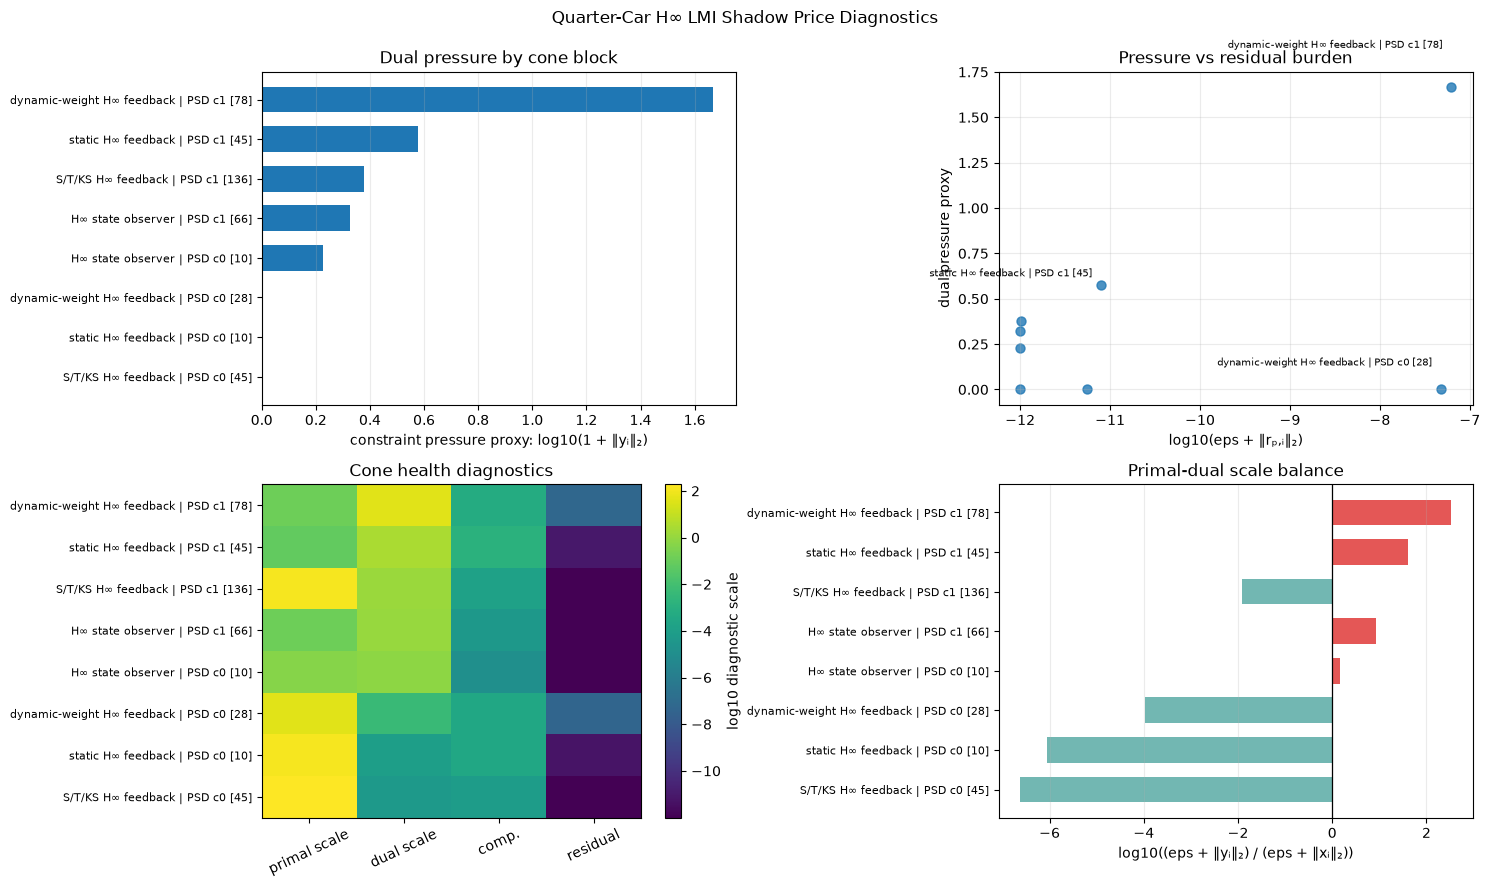

In [35]:
shadow_price_results = [
    ("static H∞ feedback", hinf_feedback_result),
    ("H∞ state observer", hinf_obs_result),
    ("dynamic-weight H∞ feedback", dynamic_hinf_feedback_result),
    ("S/T/KS H∞ feedback", mix_feedback_result),
]

plot_shadow_price_summary(
    shadow_price_results,
    title="Quarter-Car H∞ LMI Shadow Price Diagnostics",
)

© 2026 Akreon LLC.

Licensed under the Apache License, Version 2.0. See [LICENSE](../../LICENSE).